## PHASE ONE: Set up and Data ingestion
import of necessary librabries check for informations about data size, columns data type, missing column rows and handling of duplicate

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.listdir('/content/drive/MyDrive/Stock_ds')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Stock_ds'

In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [ ]:
#import of necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.experimental import enable_iterative_imputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42

In [ ]:
#import both train and test datasets
train_df = pd.read_csv('/content/drive/MyDrive/Stock_ds/train_stock_pred.csv')

In [ ]:
#check for the first 10 columns of train data set
train_df.head(10)

,Date,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Target_Next_Day_Direction
0,3/11/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,30.17,30.37,29.31,29.86,3760802,-0.01,28.59,27.07,64.90,0
1,3/12/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.86,30.35,29.06,29.27,10909971,-0.02,28.76,27.15,57.37,1
2,3/15/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.27,29.82,28.83,29.53,9405865,0.01,28.96,27.22,60.76,0
3,3/16/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.53,30.12,28.89,29.08,5090778,-0.02,29.13,27.26,56.77,0
4,3/17/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.08,29.18,28.73,28.93,10189065,-0.01,29.27,27.29,53.44,1
5,3/18/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,28.93,29.53,28.36,29.06,13114541,0.00,29.35,27.34,65.86,1
6,3/19/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.06,30.20,28.75,29.78,5649387,0.02,29.47,27.39,70.78,1
7,3/22/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.78,30.43,29.26,29.95,5896910,0.01,29.58,27.47,72.90,1
8,3/23/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,29.95,30.63,29.82,30.40,10369865,0.01,29.60,27.55,74.22,1
9,3/24/2021 0:00,AFRIBANK,AfriBank Holdings Plc,Banking,30.40,30.90,30.27,30.57,10940541,0.01,29.64,27.63,72.21,1


In [ ]:
#check for train data set column names and data type
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12110 entries, 0 to 12109
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       12110 non-null  object 
 1   Ticker                     12110 non-null  object 
 2   Company                    12110 non-null  object 
 3   Sector                     12110 non-null  object 
 4   Open                       12110 non-null  float64
 5   High                       12110 non-null  float64
 6   Low                        12110 non-null  float64
 7   Close                      12110 non-null  float64
 8   Volume                     12110 non-null  int64  
 9   Daily_Return               12110 non-null  float64
 10  SMA_10                     12110 non-null  float64
 11  SMA_50                     12110 non-null  float64
 12  RSI_14                     12110 non-null  float64
 13  Target_Next_Day_Direction  12110 non-null  int

## Phase Two: Exploratory Data Analysis
This aspect involves data cleaning, quality report handling of duplicates and several visualization to understand the various distribution of each columns with numerical data type for both the train and test data set, the visualization processes also helps determine methods that could be used to determine outliers check and handling.


In [ ]:
#check for duplicated among categorical and numerical columns in train data set
cat_col = train_df.select_dtypes(include=['object']).columns
num_col = train_df.select_dtypes(include=['float','int']).columns


print("Duplicate Check:")
print("-" * 40)
#check for duplicates specifically on the numerical columns  for train data set
train_df_num_duplicate = train_df[num_col].duplicated().sum()
print (f'Total duplicates in numerical columns: {train_df_num_duplicate}')

#check for duplicates specifically on the categorical columns  for train data set
train_df_cat_duplicate = train_df[cat_col].duplicated().sum()
print (f'Total duplicates in categorical columns: {train_df_cat_duplicate}')




Duplicate Check:
----------------------------------------
Total duplicates in numerical columns: 0
Total duplicates in categorical columns: 0


In [ ]:

#check for missing values among categorical and numerical columns in train data set
cat_col = train_df.select_dtypes(include=['object']).columns
num_col = train_df.select_dtypes(include=['float','int']).columns


print("Missing Values Check:")
print("-" * 40)
#check for missing values specifically on the numerical columns  for train data set
train_df_num_missing = train_df[num_col].isnull().sum()
print (f'Total missing values in numerical columns: {train_df_num_missing}')

#check for missing values specifically on the categorical columns  for train data set
train_df_cat_missing = train_df[cat_col].isnull().sum()
print (f'Total missing values in categorical columns: {train_df_cat_missing}')

Missing Values Check:
----------------------------------------
Total missing values in numerical columns: Open                         0
High                         0
Low                          0
Close                        0
Volume                       0
Daily_Return                 0
SMA_10                       0
SMA_50                       0
RSI_14                       0
Target_Next_Day_Direction    0
dtype: int64
Total missing values in categorical columns: Date       0
Ticker     0
Company    0
Sector     0
dtype: int64


## Brief Explanation
The above was a check for duplicates and missing values within the train data set. The columns were seperated into categorical and numerical columns and there was a return of zero duplicates and zero missing values within the data set. Now we progress into the visualization process to understand the distribution of each columns  within the  numerical data type in the data set.


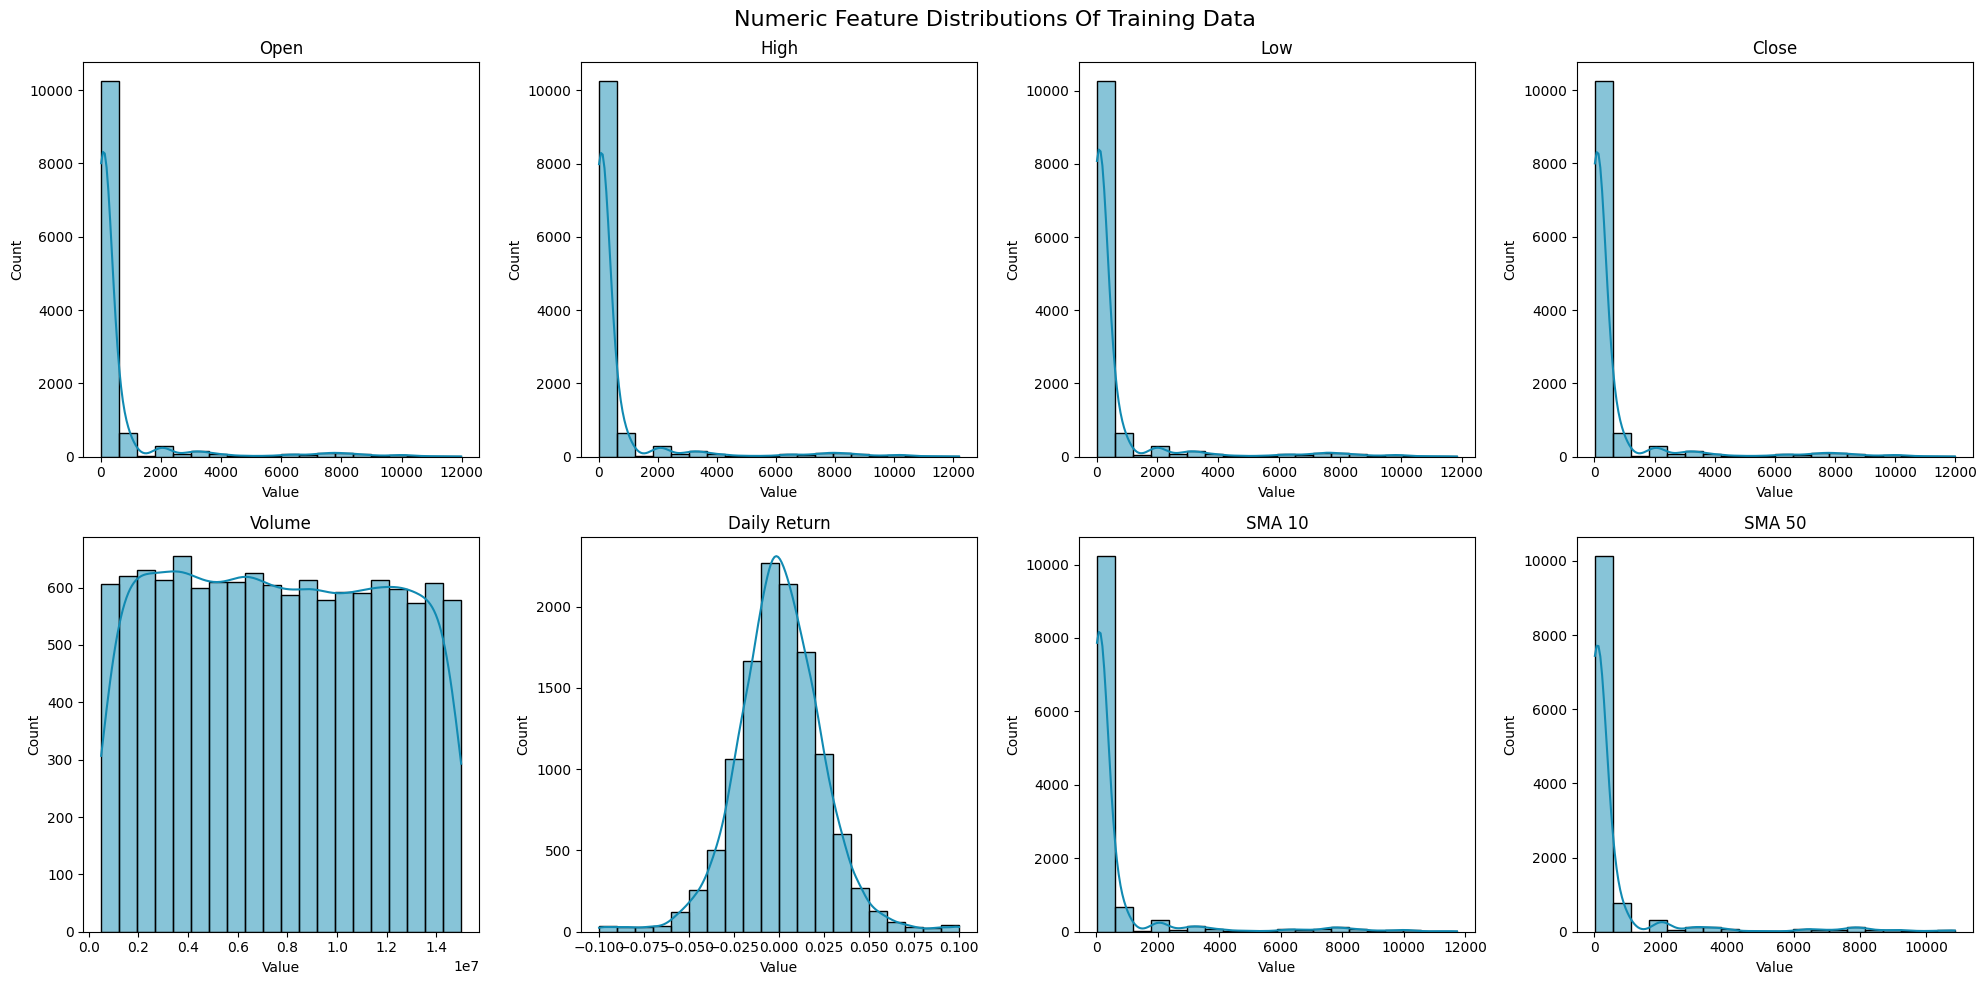

In [ ]:
num_col = train_df.select_dtypes(include=['float','int']).columns
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Numeric Feature Distributions Of Training Data', fontsize=16)

for axis, feature in zip(axes.flatten(), num_col):
    sns.histplot(train_df[feature], bins=20, kde=True, ax=axis, color='#118ab2')
    axis.set_title(feature.replace('_', ' '))
    axis.set_xlabel('Value')
    axis.set_ylabel('Count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#categorizing features with numeric columns into numeric_features
numeric_features = ['High',
'Low',
'Close',
'Volume',
'Daily_Return',
'SMA_10',
'SMA_50',
'RSI_14',
'Target_Next_Day_Direction']
#a statistical summary of the train numeric features
train_ds_stat = pd.DataFrame({'Mean': train_df[numeric_features].mean().round(3),
    'Median': train_df[numeric_features].median().round(3),
    'Std': train_df[numeric_features].std().round(3),
    'Skewness': train_df[numeric_features].skew().round(3)
}).sort_values('Mean', ascending=False)

print('\nSummary statistics for the numeric features:')
print("-" * 50)
print(train_ds_stat.to_string())
print('\n')


Summary statistics for the numeric features:
--------------------------------------------------
                                  Mean       Median          Std  Skewness
Volume                    7,668,133.71 7,607,793.50 4,183,703.13      0.03
High                            674.12        76.57     1,801.76      3.84
Close                           660.38        75.10     1,764.48      3.84
SMA_10                          657.51        75.09     1,756.71      3.85
Low                             646.32        73.46     1,726.86      3.85
SMA_50                          644.07        74.30     1,718.95      3.87
RSI_14                           50.88        51.12        16.99     -0.08
Target_Next_Day_Direction         0.50         1.00         0.50     -0.02
Daily_Return                      0.00         0.00         0.02      0.00




## Brief Explanation of the above:
The Above illustrations and data frame is a visual representaion of all features with numerical data types and their statistical summary. a quick report to break down each diagram. <br>
1. **Right-Skewed Distribution Features:** <br> **Open, High, Low, Close, SMA 10, SMA 50** These features are positively (right) skewed, meaning that the majority of observations are concentrated at lower values while a relatively small number of observations extend toward much higher values, forming a long right tail.
2. **Symmetric Distribution Feature:** **Daily Return** <br> The Daily Return feature exhibits an approximately symmetric (bell-shaped) distribution, where observations are evenly distributed around the center.
3. **Uniform Distribution Feature:** **Volume** <br> The Volume feature appears to follow a uniform distribution, where observations are spread relatively evenly across the range of values.

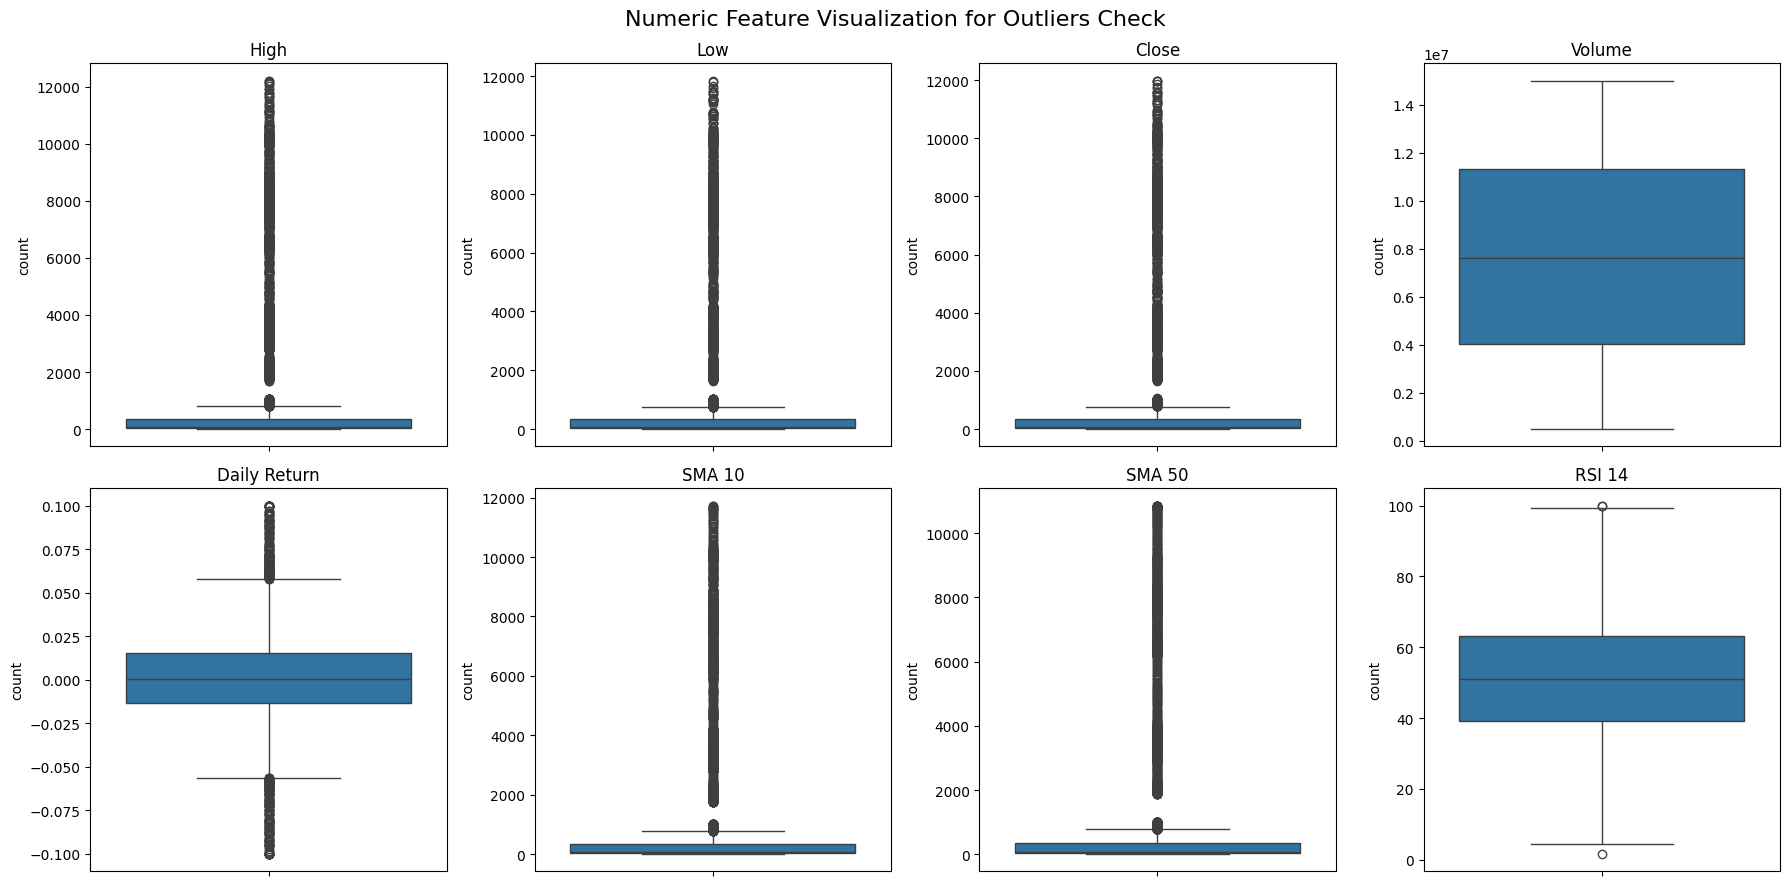

In [ ]:
# Visualizing Numeric Features for Outliers Check
num_col = train_df.select_dtypes(include=['float','int']).columns
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Numeric Feature Visualization for Outliers Check', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(data = train_df,  y = feature, ax = axis)
    axis.set_title(feature.replace('_', ' '))
    axis.set_ylabel('count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
numeric_features = [
    'High',
    'Low',
    'Close',
    'Volume',
    'Daily_Return',
    'SMA_10',
    'SMA_50',
    'RSI_14',
    'Target_Next_Day_Direction'
]

bounds = []

for col in numeric_features:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    bounds.append({
        'Column': col,
        'Lower Bound': lower,
        'Upper Bound': upper
    })

outlier = pd.DataFrame(bounds)

#print("\nOutlier Bounds")
#print("-" * 60)
#print(outlier.to_string(index=False))

pd.set_option('display.float_format', '{:,.2f}'.format)

print(outlier)






                      Column   Lower Bound   Upper Bound
0                       High       -404.49        795.23
1                        Low       -388.86        764.39
2                      Close       -396.24        779.21
3                     Volume -6,886,099.25 22,216,284.75
4               Daily_Return         -0.06          0.06
5                     SMA_10       -397.45        780.74
6                     SMA_50       -394.49        775.42
7                     RSI_14          2.90         99.31
8  Target_Next_Day_Direction         -1.50          2.50


In [ ]:
train_df[numeric_features].describe().round(4)

,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Target_Next_Day_Direction
count,"12,110.00","12,110.00","12,110.00","12,110.00","12,110.00","12,110.00","12,110.00","12,110.00","12,110.00"
mean,674.12,646.32,660.37,"7,668,133.71",0.00,657.51,644.06,50.89,0.50
std,"1,801.76","1,726.86","1,764.49","4,183,703.13",0.02,"1,756.71","1,718.95",16.99,0.50
min,14.99,14.41,14.63,"500,037.00",-0.10,15.31,16.48,1.64,0.00
25%,45.40,43.61,44.56,"4,027,294.75",-0.01,44.37,44.23,39.05,0.00
50%,76.57,73.46,75.10,"7,607,793.50",0.00,75.09,74.30,51.12,1.00
75%,345.33,331.92,338.42,"11,302,890.75",0.02,338.92,336.71,63.16,1.00
max,"12,202.91","11,839.53","11,980.32","14,999,638.00",0.10,"11,727.28","10,854.53",100.00,1.00


In [ ]:
train_df.columns

Index(['Date', 'Ticker', 'Company', 'Sector', 'Open', 'High', 'Low', 'Close',
       'Volume', 'Daily_Return', 'SMA_10', 'SMA_50', 'RSI_14',
       'Target_Next_Day_Direction'],
      dtype='object')

In [ ]:
train_df.rename(columns={'Target_Next_Day_Direction':'Target'}, inplace=True)
train_df.columns

Index(['Date', 'Ticker', 'Company', 'Sector', 'Open', 'High', 'Low', 'Close',
       'Volume', 'Daily_Return', 'SMA_10', 'SMA_50', 'RSI_14', 'Target'],
      dtype='object')

In [ ]:
#importation of test dataset
test_df = pd.read_csv('/content/drive/MyDrive/Stock_ds/test_stock_pred.csv')


In [ ]:
#check of the first few roles for the test data  set
test_df.head()

,Date,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14
0,10/31/2025,AFRIBANK,AfriBank Holdings Plc,Banking,143.13,147.18,141.30,144.98,2734489,0.01,143.84,136.02,55.65
1,11/3/2025,AFRIBANK,AfriBank Holdings Plc,Banking,144.98,145.68,144.30,144.75,12933495,-0.00,143.81,136.25,53.13
2,11/4/2025,AFRIBANK,AfriBank Holdings Plc,Banking,144.75,146.73,141.60,142.03,14453367,-0.02,143.46,136.37,33.34
3,11/5/2025,AFRIBANK,AfriBank Holdings Plc,Banking,142.03,144.44,140.09,140.91,9680351,-0.01,143.02,136.48,32.19
4,11/6/2025,AFRIBANK,AfriBank Holdings Plc,Banking,140.91,142.49,140.51,141.20,5221339,0.00,143.02,136.69,26.63


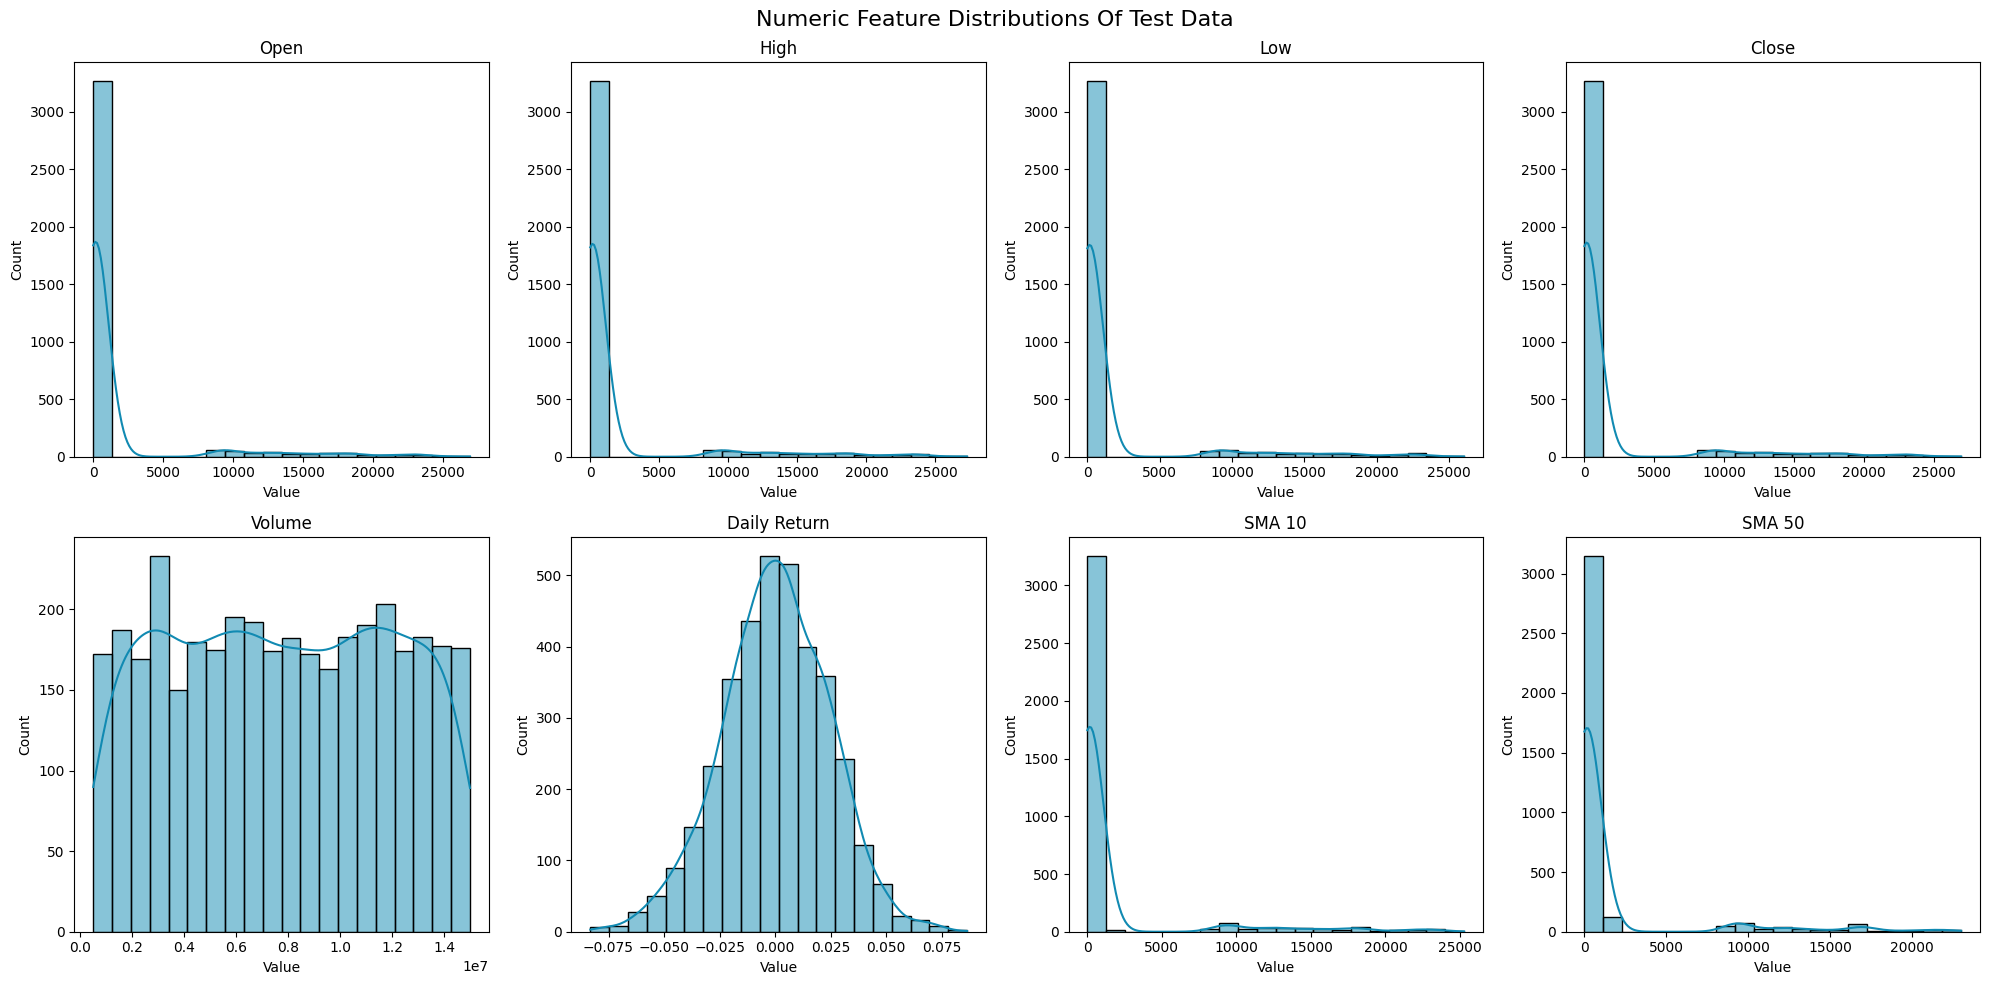

In [ ]:
#understanding distribution of each numeric features on test data set
num_col = test_df.select_dtypes(include=['float','int']).columns
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Numeric Feature Distributions Of Test Data', fontsize=16)

for axis, feature in zip(axes.flatten(), num_col):
    sns.histplot(test_df[feature], bins=20, kde=True, ax=axis, color='#118ab2')
    axis.set_title(feature.replace('_', ' '))
    axis.set_xlabel('Value')
    axis.set_ylabel('Count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

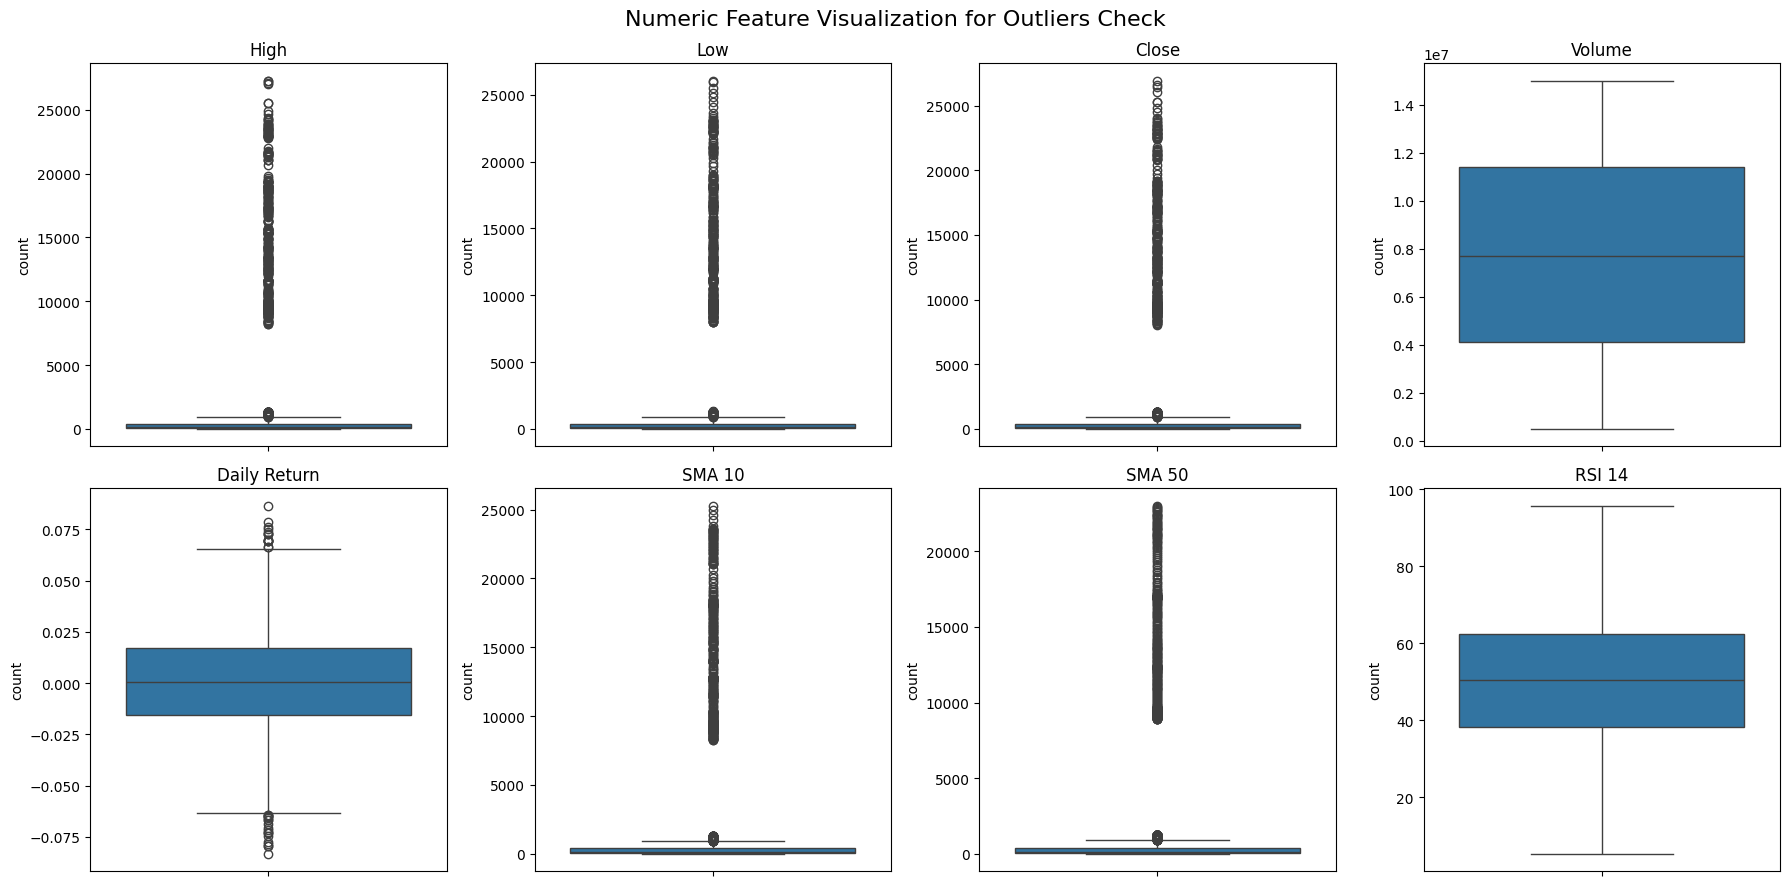

In [ ]:
# Visualizing Numeric Features for Outliers Check
num_col = test_df.select_dtypes(include=['float','int']).columns
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Numeric Feature Visualization for Outliers Check', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(data = test_df,  y = feature, ax = axis)
    axis.set_title(feature.replace('_', ' '))
    axis.set_ylabel('count')

#axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

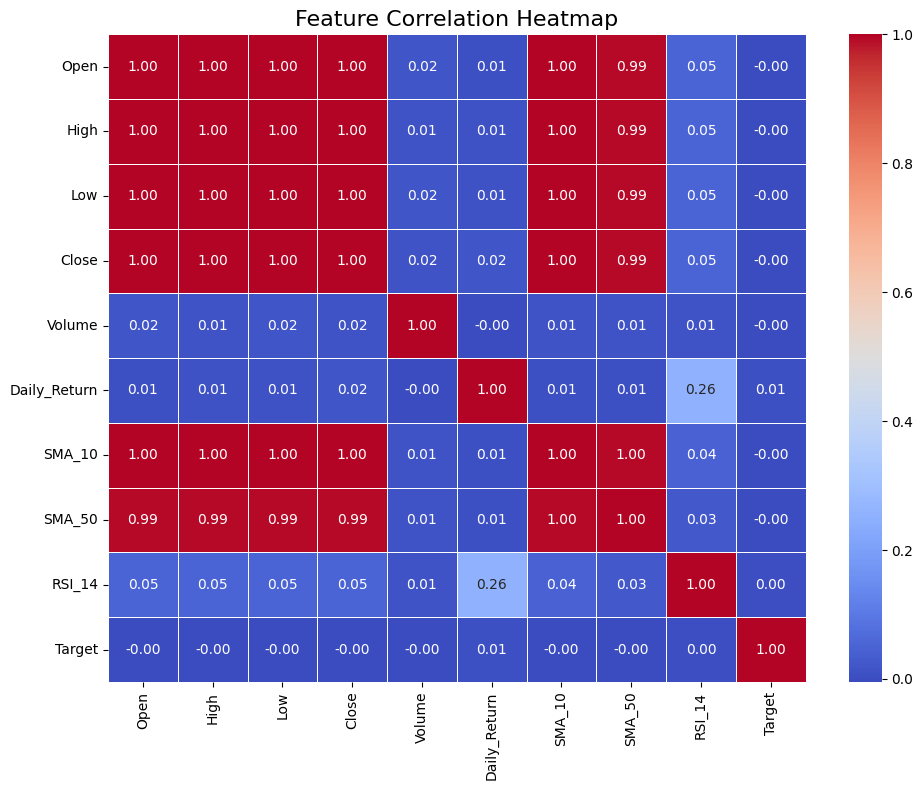

In [ ]:
plt.figure(figsize=(10, 8))
# select only numerical columns for correlation
corr_df = train_df.select_dtypes(include=[np.number])
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
#break down of date into year, month and dayin seperate columns
train_df['Date'] = pd.to_datetime(train_df['Date'])

train_df['Year'] = train_df['Date'].dt.year
train_df['Month'] = train_df['Date'].dt.month
train_df['Day']= train_df['Date'].dt.day

train_df.drop(columns=['Date'], inplace = True)

In [ ]:
train_df.head()

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Target,Year,Month,Day
0,AFRIBANK,AfriBank Holdings Plc,Banking,30.17,30.37,29.31,29.86,3760802,-0.01,28.59,27.07,64.90,0,2021,3,11
1,AFRIBANK,AfriBank Holdings Plc,Banking,29.86,30.35,29.06,29.27,10909971,-0.02,28.76,27.15,57.37,1,2021,3,12
2,AFRIBANK,AfriBank Holdings Plc,Banking,29.27,29.82,28.83,29.53,9405865,0.01,28.96,27.22,60.76,0,2021,3,15
3,AFRIBANK,AfriBank Holdings Plc,Banking,29.53,30.12,28.89,29.08,5090778,-0.02,29.13,27.26,56.77,0,2021,3,16
4,AFRIBANK,AfriBank Holdings Plc,Banking,29.08,29.18,28.73,28.93,10189065,-0.01,29.27,27.29,53.44,1,2021,3,17


In [ ]:
#break down of date into year, month and dayin seperate columns
test_df['Date'] = pd.to_datetime(test_df['Date'])

test_df['Year'] = test_df['Date'].dt.year
test_df['Month'] = test_df['Date'].dt.month
test_df['Day']= test_df['Date'].dt.day

test_df.drop(columns=['Date'], inplace = True)

## Brief Explanation<br>
The date column was left aligned which indicated that it was been recognised on the data frame as a text in order for it to be recognised as a number within the data frame date was broken down and extration of day, month and yearr took place in order for a smooth execution of its standard scaling.

In [ ]:
test_df.head()

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Year,Month,Day
0,AFRIBANK,AfriBank Holdings Plc,Banking,143.13,147.18,141.30,144.98,2734489,0.01,143.84,136.02,55.65,2025,10,31
1,AFRIBANK,AfriBank Holdings Plc,Banking,144.98,145.68,144.30,144.75,12933495,-0.00,143.81,136.25,53.13,2025,11,3
2,AFRIBANK,AfriBank Holdings Plc,Banking,144.75,146.73,141.60,142.03,14453367,-0.02,143.46,136.37,33.34,2025,11,4
3,AFRIBANK,AfriBank Holdings Plc,Banking,142.03,144.44,140.09,140.91,9680351,-0.01,143.02,136.48,32.19,2025,11,5
4,AFRIBANK,AfriBank Holdings Plc,Banking,140.91,142.49,140.51,141.20,5221339,0.00,143.02,136.69,26.63,2025,11,6


## Brief Explanation: <br>
The data set was intentionally splitted into train and test respectively,the train data set contains **70%** of the original data set while then test data set contains **30%**.  both data set would have their outliers, encoding and scaling done through the same process through a pipeline. The pipeline would involve the columns with numerical datatype and it process would involve capping of outliers into **IQR** upper and lower bound and then the standard scaler of the numerical features. Firstly, we split the data then fit only the train data set inorder to avoid leakage, the scaler and outlier_handler learns only from the x_train.

## Phase Four:  Feature Engineering
In this section, both train and test data set would be passed through a pipe line, within the pipeline the `capping of outliers would be done` through `outliercapper`, the `standard scaling` of the numerical features and the `one hot encoding` for the categorical features would also occur, The train data set would firstly be splitted into the **X_train, X_val,y_train and y_val respectively** the splitting would be a 80% - 20 % splitting. after which we'd move into the aspect of baseline modelling.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer

class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        Q1 = X.quantile(0.25)
        Q3 = X.quantile(0.75)
        IQR = Q3 - Q1
        self.lower_bound_ = Q1 - self.factor * IQR
        self.upper_bound_ = Q3 + self.factor * IQR
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X = X.clip(lower=self.lower_bound_, upper=self.upper_bound_, axis=1)
        return X.values


# drop of target from train
target_col = "Target"
X_train_full = train_df.drop(columns=[target_col])
y_train_full = train_df[target_col]
X_test = test_df.copy()
#
numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Daily_Return", "SMA_10", "SMA_50", "RSI_14","Year","Month","Day"]
categorical_cols = ["Ticker","Company","Sector"]


# Split train into train/val before any form of fitting happens to avoid data leakage. This ensures that the validation set remains unseen during the training process.
X_train_sub, X_val, y_train_sub, y_val = train_test_split( X_train_full, y_train_full, test_size=0.2, random_state=42)


# clipping of outliers fitting on train_sub only, but transform includes val/test
capper = OutlierCapper(factor=1.5)

X_train_sub_num_capped = capper.fit_transform(X_train_sub[numeric_cols])
X_val_num_capped       = capper.transform(X_val[numeric_cols])
X_test_num_capped      = capper.transform(X_test[numeric_cols])


# scaling and fitting on the capped train_sub numeric data only, but transform includes val/test
scaler = StandardScaler()

X_train_sub_num_scaled = scaler.fit_transform(X_train_sub_num_capped)
X_val_num_scaled       = scaler.transform(X_val_num_capped)
X_test_num_scaled      = scaler.transform(X_test_num_capped)

# wrap back into DataFrames with original numeric column names/index cos standard scalar is returned in form of numpy array
X_train_sub_num_scaled = pd.DataFrame(X_train_sub_num_scaled, columns=numeric_cols, index=X_train_sub.index)
X_val_num_scaled       = pd.DataFrame(X_val_num_scaled, columns=numeric_cols, index=X_val.index)
X_test_num_scaled      = pd.DataFrame(X_test_num_scaled, columns=numeric_cols, index=X_test.index)


# encoding fit on train_sub categorical data only, but transform includes val/test
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_sub_cat_encoded = encoder.fit_transform(X_train_sub[categorical_cols])
X_val_cat_encoded       = encoder.transform(X_val[categorical_cols])
X_test_cat_encoded      = encoder.transform(X_test[categorical_cols])

ohe_cols = encoder.get_feature_names_out(categorical_cols)

X_train_sub_cat_encoded = pd.DataFrame(X_train_sub_cat_encoded, columns=ohe_cols, index=X_train_sub.index)
X_val_cat_encoded       = pd.DataFrame(X_val_cat_encoded, columns=ohe_cols, index=X_val.index)
X_test_cat_encoded      = pd.DataFrame(X_test_cat_encoded, columns=ohe_cols, index=X_test.index)


# merge numeric (capped+scaled) and categorical (encoded) back together
X_train_sub_final = pd.concat([X_train_sub_num_scaled, X_train_sub_cat_encoded], axis=1)
X_val_final        = pd.concat([X_val_num_scaled, X_val_cat_encoded], axis=1)
X_test_final       = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)

print(f"train_full: {X_train_full.shape[0]}")
print(f"train_sub:  {X_train_sub.shape[0]}")
print(f"val:        {X_val.shape[0]}")
print(f"test:       {X_test.shape[0]}")





train_full: 12110
train_sub:  9688
val:        2422
test:       3630


In [ ]:
X_train_sub_final.head()

,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Year,...,Company_GT Capital Holdings Plc,Company_MTN Nigeria Communications Plc,Company_Nigerian Energy Resources Plc,Company_Unilever Nigeria Plc,Company_Zenith Capital Bank Plc,Sector_Banking,Sector_Consumer Goods,Sector_Industrial Goods,Sector_Oil & Gas,Sector_Telecommunications
108,-0.70,-0.69,-0.70,-0.69,-0.26,1.60,-0.70,-0.69,-0.72,-1.48,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
8323,2.13,2.13,2.13,2.13,-1.36,1.61,2.14,2.14,0.65,1.47,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
11696,-0.75,-0.75,-0.75,-0.75,0.12,0.18,-0.75,-0.73,-1.28,0.73,...,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00
2929,-0.72,-0.72,-0.72,-0.72,1.51,-1.13,-0.72,-0.73,1.19,-0.01,...,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
9100,-0.60,-0.61,-0.60,-0.61,0.69,-0.63,-0.61,-0.60,0.66,-0.01,...,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00


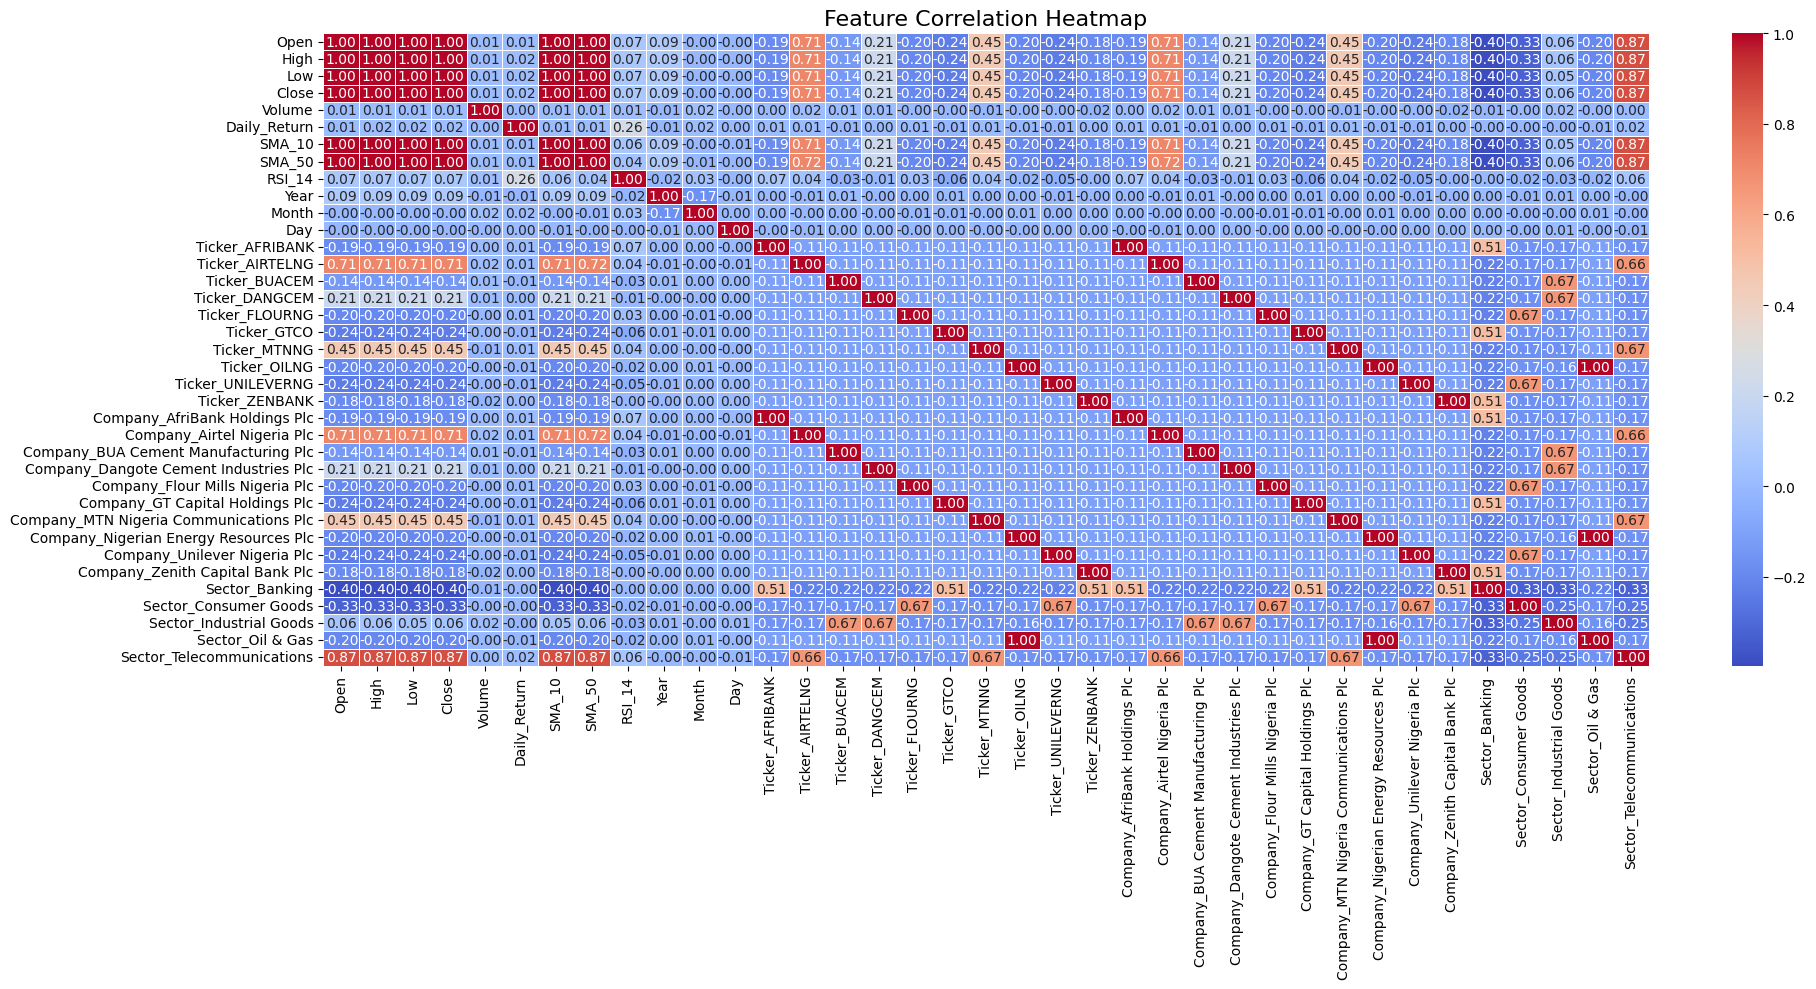

In [ ]:
# feature Correlation Heatmap
plt.figure(figsize=(20, 10))
# select only numerical columns for correlation
corr_fe_df = X_train_sub_final.select_dtypes(include=[np.number])
sns.heatmap(corr_fe_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

## Phase Five: Base Line Modeling
Train the a baseline random forest model in order to establish the initial performance metrics.

In [ ]:
# baseline model: Random Forest Classifier
baseline_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

# fit on train_sub only
baseline_rf.fit(X_train_sub_final, y_train_sub)

# Predict on validation set
val_preds = baseline_rf.predict(X_val_final)
val_probs = baseline_rf.predict_proba(X_val_final)[:, 1]  # needed for ROC-AUC

# metrics
accuracy  = accuracy_score(y_val, val_preds)
precision = precision_score(y_val, val_preds)
recall    = recall_score(y_val, val_preds)
f1        = f1_score(y_val, val_preds)
roc_auc   = roc_auc_score(y_val, val_probs)

print("=== Baseline Random Forest — Validation Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:\n", classification_report(y_val, val_preds))
print("Confusion Matrix:\n", confusion_matrix(y_val, val_preds))

# --- Feature importance ---
feature_importances = pd.Series(
    baseline_rf.feature_importances_, index=X_train_sub_final.columns
).sort_values(ascending=False)

print("\nTop Feature Importances:\n", feature_importances)

=== Baseline Random Forest — Validation Metrics ===
Accuracy:  0.5223
Precision: 0.5191
Recall:    0.5307
F1 Score:  0.5248
ROC-AUC:   0.5286

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.51      0.52      1218
           1       0.52      0.53      0.52      1204

    accuracy                           0.52      2422
   macro avg       0.52      0.52      0.52      2422
weighted avg       0.52      0.52      0.52      2422

Confusion Matrix:
 [[626 592]
 [565 639]]

Top Feature Importances:
 Volume                                   0.11
Daily_Return                             0.11
RSI_14                                   0.11
Day                                      0.09
SMA_50                                   0.08
SMA_10                                   0.08
High                                     0.07
Low                                      0.07
Close                                    0.07
Open                   

##

In [ ]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rfc_param_dist = {
    'n_estimators': randint(300, 800),
    'max_depth': randint(8, 20),
    'max_features': ['sqrt', 'log2', None],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5),
    'class_weight': ['balanced', None],
    'bootstrap': [True, False]

}

rfc_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=rfc_param_dist,
    n_iter=10,
    scoring='recall',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

rfc_search.fit(X_train_sub_final, y_train_sub)

best_rfc = rfc_search.best_estimator_

print("Best Parameters:")
print(rfc_search.best_params_)

val_preds = best_rfc.predict(X_val_final)
val_probs = best_rfc.predict_proba(X_val_final)[:, 1]

accuracy = accuracy_score(y_val, val_preds)
precision = precision_score(y_val, val_preds)
recall = recall_score(y_val, val_preds)
f1 = f1_score(y_val, val_preds)
roc_auc = roc_auc_score(y_val, val_probs)

print("\n=== Tuned Random Forest Validation Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Best Parameters:
{'bootstrap': False, 'class_weight': 'balanced', 'max_depth': 9, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 8, 'n_estimators': 727}

=== Tuned Random Forest Validation Metrics ===
Accuracy:  0.5033
Precision: 0.5002
Recall:    0.8754
F1 Score:  0.6367
ROC-AUC:   0.4993


In [ ]:
# extract the tuned Random Forest model
best_rf = rfc_search.best_estimator_

# create a dataframe containing the feature names and their importance scores
feature_importance = pd.DataFrame({ "Feature": X_train_sub_final.columns, "Importance": best_rf.feature_importances_ })

# select the top 10 features
top_features = feature_importance.head(10).sort_values( by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.gca().invert_yaxis()

plt.title("Top 15 Feature Importance of Tuned Random Forest Classifier")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

NameError: name 'rfc_search' is not defined

## Phase Six: Domain Knowledge Informed Preprocessing
Due to the not so impressive performance of the `random forest classifier` on the trained data set which is like a first indicator that the model doesn't have enough features to learn from,  the domain knowledge would be applied in such a way that the existing feature is used to derive new features.

In [ ]:



# create a function that adds all stock market domain knowledge features
def create_domain_features(df):

    # make a copy so the original dataset is not modified
    df = df.copy()


    # macd (moving average convergence divergence)
    # calculate the short-term exponential moving average
    ema12 = df["Close"].ewm(span=12, adjust=False).mean()
    # calculate the long-term exponential moving average
    ema26 = df["Close"].ewm(span=26, adjust=False).mean()

    # calculate the macd line
    df["MACD"] = ema12 - ema26

    # calculate the signal line
    df["MACD_Signal"] = (df["MACD"].ewm(span=9, adjust=False).mean())


    # atr (average true range)
    # get yesterday's closing price
    previous_close = df["Close"].shift(1)

    # calculate the three true range values
    tr1 = df["High"] - df["Low"]
    tr2 = (df["High"] - previous_close).abs()
    tr3 = (df["Low"] - previous_close).abs()

    # choose the maximum true range
    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

    # calculate the 14-day atr
    df["ATR_14"] = true_range.rolling(window=14).mean()

    # obv (on balance volume)
    # determine whether price moved up or down
    direction = np.sign(df["Close"].diff())

    # accumulate buying and selling pressure
    df["OBV"] = (direction.fillna(0) * df["Volume"]).cumsum()

    # lagged return
    # move yesterday's return into today's row
    df["Lagged_Return"] = df["Daily_Return"].shift(1)


    # stochastic oscillator
    # find the lowest low over the previous 14 days
    low14 = df["Low"].rolling(window=14).min()

    # find the highest high over the previous 14 days
    high14 = df["High"].rolling(window=14).max()

    # calculate the stochastic oscillator
    df["Stochastic"] = ((df["Close"] - low14)/ (high14 - low14)) * 100

    # return the updated dataframe
    return df


# apply the feature engineering to both datasets
train_df_domain= create_domain_features(train_df)
test_df_domain= create_domain_features(test_df)

In [ ]:
train_df_domain.head()

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,...,Target,Year,Month,Day,MACD,MACD_Signal,ATR_14,OBV,Lagged_Return,Stochastic
0,AFRIBANK,AfriBank Holdings Plc,Banking,30.17,30.37,29.31,29.86,3760802,-0.01,28.59,...,0,2021,3,11,0.00,0.00,NaN,0.00,NaN,NaN
1,AFRIBANK,AfriBank Holdings Plc,Banking,29.86,30.35,29.06,29.27,10909971,-0.02,28.76,...,1,2021,3,12,-0.05,-0.01,NaN,"-10,909,971.00",-0.01,NaN
2,AFRIBANK,AfriBank Holdings Plc,Banking,29.27,29.82,28.83,29.53,9405865,0.01,28.96,...,0,2021,3,15,-0.06,-0.02,NaN,"-1,504,106.00",-0.02,NaN
3,AFRIBANK,AfriBank Holdings Plc,Banking,29.53,30.12,28.89,29.08,5090778,-0.02,29.13,...,0,2021,3,16,-0.11,-0.04,NaN,"-6,594,884.00",0.01,NaN
4,AFRIBANK,AfriBank Holdings Plc,Banking,29.08,29.18,28.73,28.93,10189065,-0.01,29.27,...,1,2021,3,17,-0.16,-0.06,NaN,"-16,783,949.00",-0.02,NaN


In [ ]:
test_df_domain.head(100)

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,...,RSI_14,Year,Month,Day,MACD,MACD_Signal,ATR_14,OBV,Lagged_Return,Stochastic
0,AFRIBANK,AfriBank Holdings Plc,Banking,143.13,147.18,141.30,144.98,2734489,0.01,143.84,...,55.65,2025,10,31,0.00,0.00,NaN,0.00,NaN,NaN
1,AFRIBANK,AfriBank Holdings Plc,Banking,144.98,145.68,144.30,144.75,12933495,-0.00,143.81,...,53.13,2025,11,3,-0.02,-0.00,NaN,"-12,933,495.00",0.01,NaN
2,AFRIBANK,AfriBank Holdings Plc,Banking,144.75,146.73,141.60,142.03,14453367,-0.02,143.46,...,33.34,2025,11,4,-0.25,-0.05,NaN,"-27,386,862.00",-0.00,NaN
3,AFRIBANK,AfriBank Holdings Plc,Banking,142.03,144.44,140.09,140.91,9680351,-0.01,143.02,...,32.19,2025,11,5,-0.52,-0.15,NaN,"-37,067,213.00",-0.02,NaN
4,AFRIBANK,AfriBank Holdings Plc,Banking,140.91,142.49,140.51,141.20,5221339,0.00,143.02,...,26.63,2025,11,6,-0.70,-0.26,NaN,"-31,845,874.00",-0.01,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,AFRIBANK,AfriBank Holdings Plc,Banking,109.07,114.33,107.63,112.45,991072,0.03,112.35,...,54.11,2026,3,13,-1.39,-1.59,4.74,"-49,924,659.00",-0.04,37.60
96,AFRIBANK,AfriBank Holdings Plc,Banking,112.45,113.72,111.58,113.35,5333177,0.01,112.79,...,56.62,2026,3,16,-1.24,-1.52,4.61,"-44,591,482.00",0.03,44.29
97,AFRIBANK,AfriBank Holdings Plc,Banking,113.35,114.96,110.99,111.90,12878226,-0.01,113.00,...,53.46,2026,3,17,-1.22,-1.46,4.65,"-57,469,708.00",0.01,32.37
98,AFRIBANK,AfriBank Holdings Plc,Banking,111.90,113.53,109.01,110.48,11117244,-0.01,113.12,...,50.39,2026,3,18,-1.31,-1.43,4.73,"-68,586,952.00",-0.01,21.59


In [ ]:
train_df_domain.isnull().sum()

,0
Ticker,0
Company,0
Sector,0
Open,0
High,0
Low,0
Close,0
Volume,0
Daily_Return,0
SMA_10,0


In [ ]:
# placing empty into a data frame
train_domain_missing = pd.DataFrame ({'Columns': train_df_domain.columns,
                               'Missing_Count':train_df_domain.isnull().sum(),
                               'Missing_Percentage': (train_df_domain.isnull().sum() / len(train_df) * 100).round(2)},
                               )

train_domain_missing = train_domain_missing[train_domain_missing['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

print("\n")
print(train_domain_missing.to_string(index=False))
print("\n")




      Columns  Missing_Count  Missing_Percentage
       ATR_14             13                0.11
   Stochastic             13                0.11
Lagged_Return              1                0.01




In [ ]:

test_domain_missing = pd.DataFrame ({'Columns': test_df_domain.columns,
                               'Missing_Count':test_df_domain.isnull().sum(),
                               'Missing_Percentage': (test_df_domain.isnull().sum() / len(train_df) * 100).round(2)},
                               )

test_domain_missing = test_domain_missing[test_domain_missing['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

print("\n")
print(test_domain_missing.to_string(index=False))
print("\n")




      Columns  Missing_Count  Missing_Percentage
       ATR_14             13                0.11
   Stochastic             13                0.11
Lagged_Return              1                0.01




Imputation method comparison using masked observed values:
Method  RMSE
  MICE 49.22
  Mean 49.62
Median 51.91
   KNN 56.81


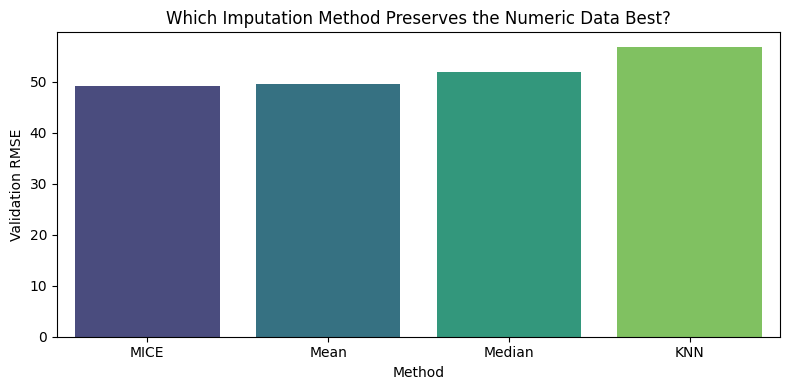

In [ ]:
#import necessary libraries
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
#from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_squared_error

# select missing numeric column for train
train_numeric_features = train_df_domain.select_dtypes(
    include=['int64', 'float64']
).columns [ train_df_domain.select_dtypes(include=['int64', 'float64']).isnull().any()]


#test_numeric_features = test_df_domain.select_dtypes(
   # include=['int64', 'float64']
#).columns

comparison_source = train_df_domain[train_numeric_features].copy()
observed_positions = np.argwhere(comparison_source.notna().to_numpy())
rng = np.random.default_rng(42)
mask_size = max(1, int(len(observed_positions) * 0.1))
selected_positions = observed_positions[rng.choice(len(observed_positions), size=mask_size, replace=False)]
validation_mask = pd.DataFrame(False, index=comparison_source.index, columns=comparison_source.columns)
for row_idx, col_idx in selected_positions:
    validation_mask.iat[row_idx, col_idx] = True

masked_data = comparison_source.mask(validation_mask)
scaler = StandardScaler()
scaled_masked = pd.DataFrame(
    scaler.fit_transform(masked_data),
    columns=train_numeric_features,
    index=masked_data.index
)

imputer_trials = {
    'Mean': SimpleImputer(strategy='mean'),
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5, weights='distance'),
    'MICE': IterativeImputer(random_state=42, max_iter=20)
}

comparison_rows = []
validation_mask_array = validation_mask.to_numpy()
actual_values = comparison_source.to_numpy()[validation_mask_array]

for method_name, imputer in imputer_trials.items():
    imputed_scaled = pd.DataFrame(
        imputer.fit_transform(scaled_masked),
        columns=train_numeric_features,
        index=scaled_masked.index
    )
    imputed_values = pd.DataFrame(
        scaler.inverse_transform(imputed_scaled),
        columns=train_numeric_features,
        index=scaled_masked.index
    )

    predicted_values = imputed_values.to_numpy()[validation_mask_array]
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    comparison_rows.append({
        'Method': method_name,
        'RMSE': rmse
    })

comparison_results = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
print('Imputation method comparison using masked observed values:')
print(comparison_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_results, x='Method', y='RMSE', hue='Method', palette='viridis', legend=False)
plt.title('Which Imputation Method Preserves the Numeric Data Best?')
plt.xlabel('Method')
plt.ylabel('Validation RMSE')
plt.tight_layout()
plt.show()


Imputation method comparison using masked observed values:
Method   RMSE
  MICE 167.14
  Mean 167.52
   KNN 172.89
Median 175.65


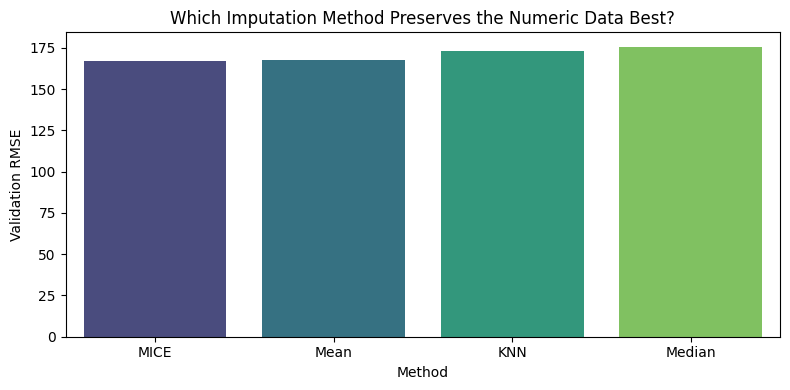

In [ ]:
#from sklearn.impute import IterativeImputer
#from sklearn.metrics import mean_squared_error

# select missing  numerical columns for test data set
test_numeric_features = test_df_domain.select_dtypes(
    include=['int64', 'float64']
).columns [ test_df_domain.select_dtypes(include=['int64', 'float64']).isnull().any()]

test_numeric_features = test_numeric_features.drop(
    'Target',
    errors='ignore'
 )

#test_numeric_features = test_df_domain.select_dtypes(
   # include=['int64', 'float64']
#).columns

comparison_source = test_df_domain[test_numeric_features].copy()
observed_positions = np.argwhere(comparison_source.notna().to_numpy())
rng = np.random.default_rng(42)
mask_size = max(1, int(len(observed_positions) * 0.1))
selected_positions = observed_positions[rng.choice(len(observed_positions), size=mask_size, replace=False)]
validation_mask = pd.DataFrame(False, index=comparison_source.index, columns=comparison_source.columns)
for row_idx, col_idx in selected_positions:
    validation_mask.iat[row_idx, col_idx] = True

masked_data = comparison_source.mask(validation_mask)
scaler = StandardScaler()
scaled_masked = pd.DataFrame(
    scaler.fit_transform(masked_data),
    columns=test_numeric_features,
    index=masked_data.index
)

imputer_trials = {
    'Mean': SimpleImputer(strategy='mean'),
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5, weights='distance'),
    'MICE': IterativeImputer(random_state=42, max_iter=20)
}

comparison_rows = []
validation_mask_array = validation_mask.to_numpy()
actual_values = comparison_source.to_numpy()[validation_mask_array]

for method_name, imputer in imputer_trials.items():
    imputed_scaled = pd.DataFrame(
        imputer.fit_transform(scaled_masked),
        columns=test_numeric_features,
        index=scaled_masked.index
    )
    imputed_values = pd.DataFrame(
        scaler.inverse_transform(imputed_scaled),
        columns=test_numeric_features,
        index=scaled_masked.index
    )

    predicted_values = imputed_values.to_numpy()[validation_mask_array]
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    comparison_rows.append({
        'Method': method_name,
        'RMSE': rmse
    })

comparison_results = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
print('Imputation method comparison using masked observed values:')
print(comparison_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_results, x='Method', y='RMSE', hue='Method', palette='viridis', legend=False)
plt.title('Which Imputation Method Preserves the Numeric Data Best?')
plt.xlabel('Method')
plt.ylabel('Validation RMSE')
plt.tight_layout()
plt.show()

In [ ]:
# select numerical columns for train dataset
train_numeric_features = train_df_domain.select_dtypes(
    include=['int64', 'float64']).columns

# identify only numerical columns with missing values
missing_numeric_features = train_numeric_features[
    train_df_domain[train_numeric_features].isnull().any()]

print("Numerical columns with missing values:")
print(missing_numeric_features.tolist())

# create a copy of the training dataset
train_df_imputer = train_df_domain.copy()
# initialize MICE

mice_imputer = IterativeImputer(random_state=42, max_iter=20)


# apply MICE only to missing numerical columns
train_df_imputer[missing_numeric_features] = mice_imputer.fit_transform(
    train_df_domain[missing_numeric_features])


# Check missing values after imputation
print("\nMissing values after MICE:")
print(
    train_df_imputer[missing_numeric_features].isnull().sum())


print("\nShape after MICE:")
print(train_df_imputer.shape)

Numerical columns with missing values:
['ATR_14', 'Lagged_Return', 'Stochastic']

Missing values after MICE:
ATR_14           0
Lagged_Return    0
Stochastic       0
dtype: int64

Shape after MICE:
(12110, 22)


In [ ]:
# select numerical columns for train dataset
test_numeric_features = test_df_domain.select_dtypes(
    include=['int64', 'float64']).columns

# identify only numerical columns with missing values
test_missing_numeric_features = test_numeric_features[
    test_df_domain[test_numeric_features].isnull().any()]

print("Numerical columns with missing values:")
print(missing_numeric_features.tolist())

# create a copy of the training dataset
test_df_imputer = test_df_domain.copy()
# initialize MICE

mice_imputer = IterativeImputer(random_state=42, max_iter=20)


# apply MICE only to missing numerical columns
test_df_imputer[test_missing_numeric_features] = mice_imputer.fit_transform(
    test_df_domain[test_missing_numeric_features])


# Check missing values after imputation
print("\nMissing values after MICE:")
print(
    test_df_imputer[test_missing_numeric_features].isnull().sum())


print("\nShape after MICE:")
print(test_df_imputer.shape)

Numerical columns with missing values:
['ATR_14', 'Lagged_Return', 'Stochastic']

Missing values after MICE:
ATR_14           0
Lagged_Return    0
Stochastic       0
dtype: int64

Shape after MICE:
(3630, 21)


In [ ]:
train_df_imputer.rename(columns={'Target_Next_Day_Direction':'Target'}, inplace=True)
train_df_imputer.columns

Index(['Ticker', 'Company', 'Sector', 'Open', 'High', 'Low', 'Close', 'Volume',
       'Daily_Return', 'SMA_10', 'SMA_50', 'RSI_14', 'Target', 'Year', 'Month',
       'Day', 'MACD', 'MACD_Signal', 'ATR_14', 'OBV', 'Lagged_Return',
       'Stochastic'],
      dtype='object')

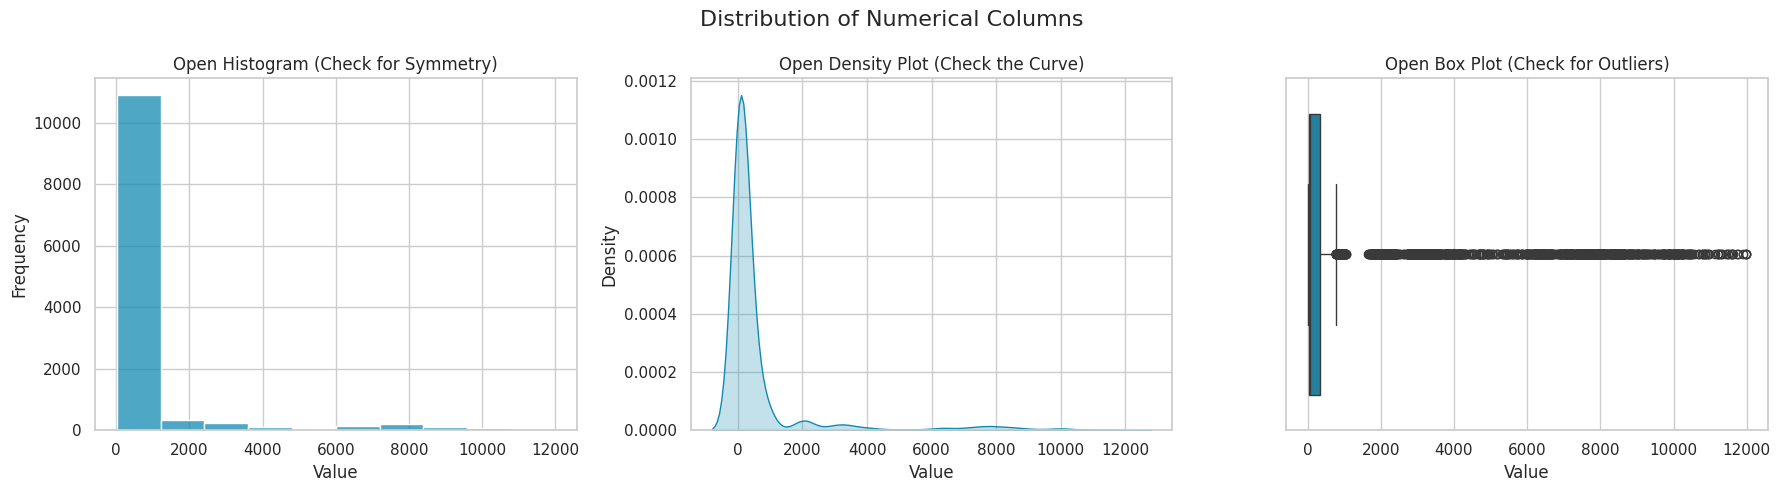

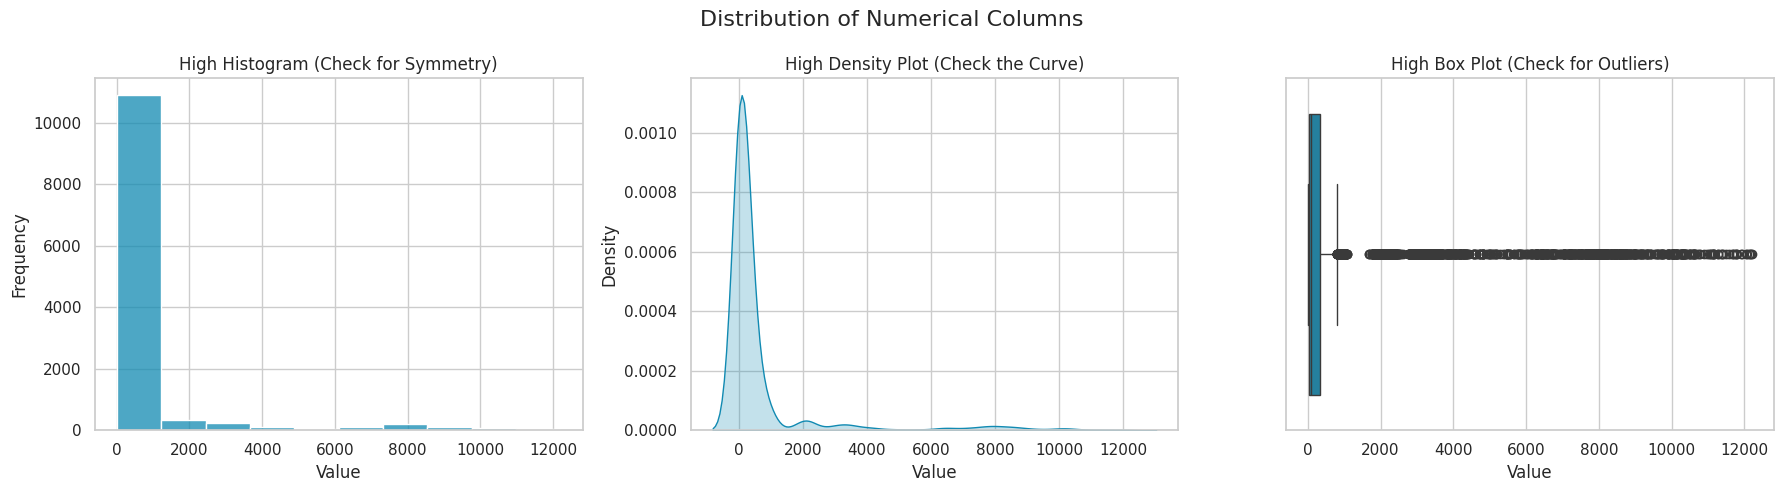

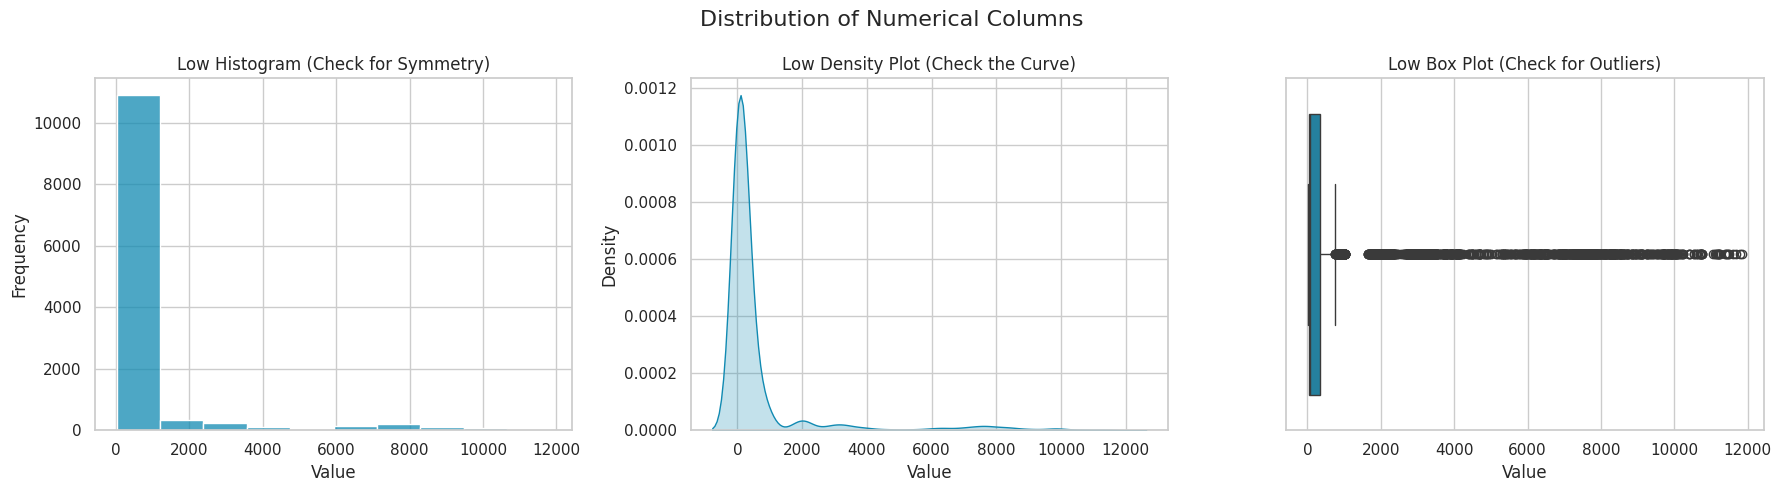

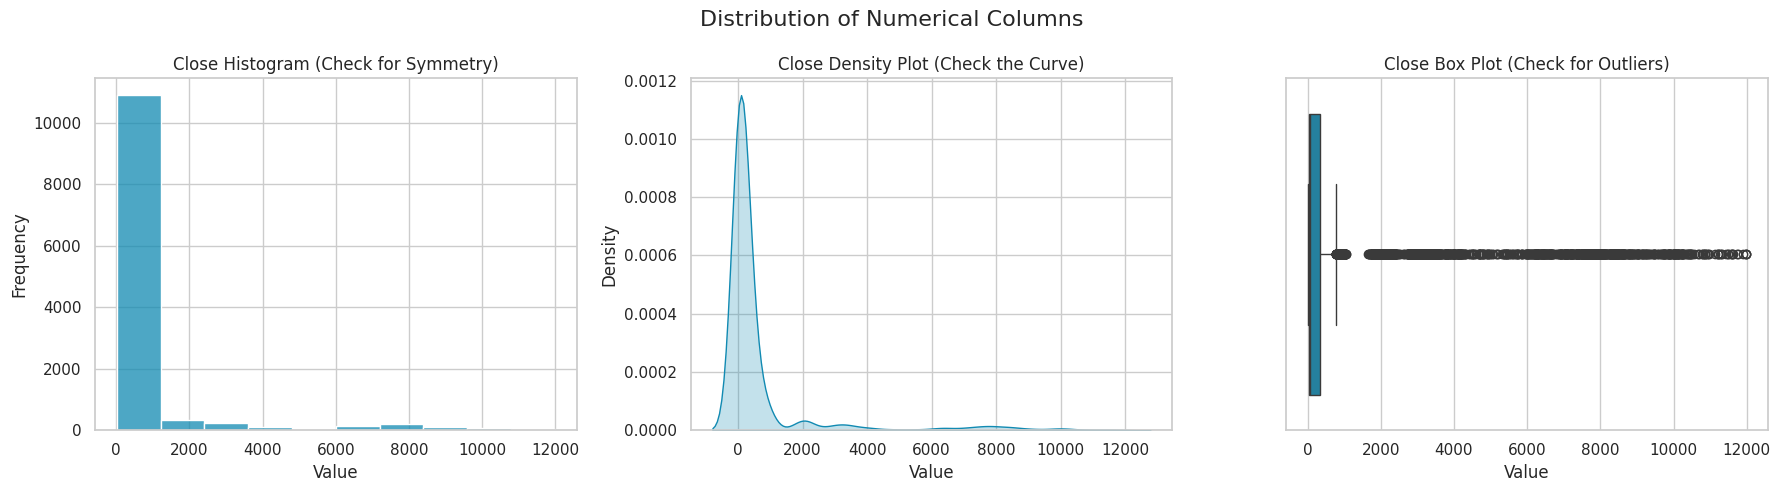

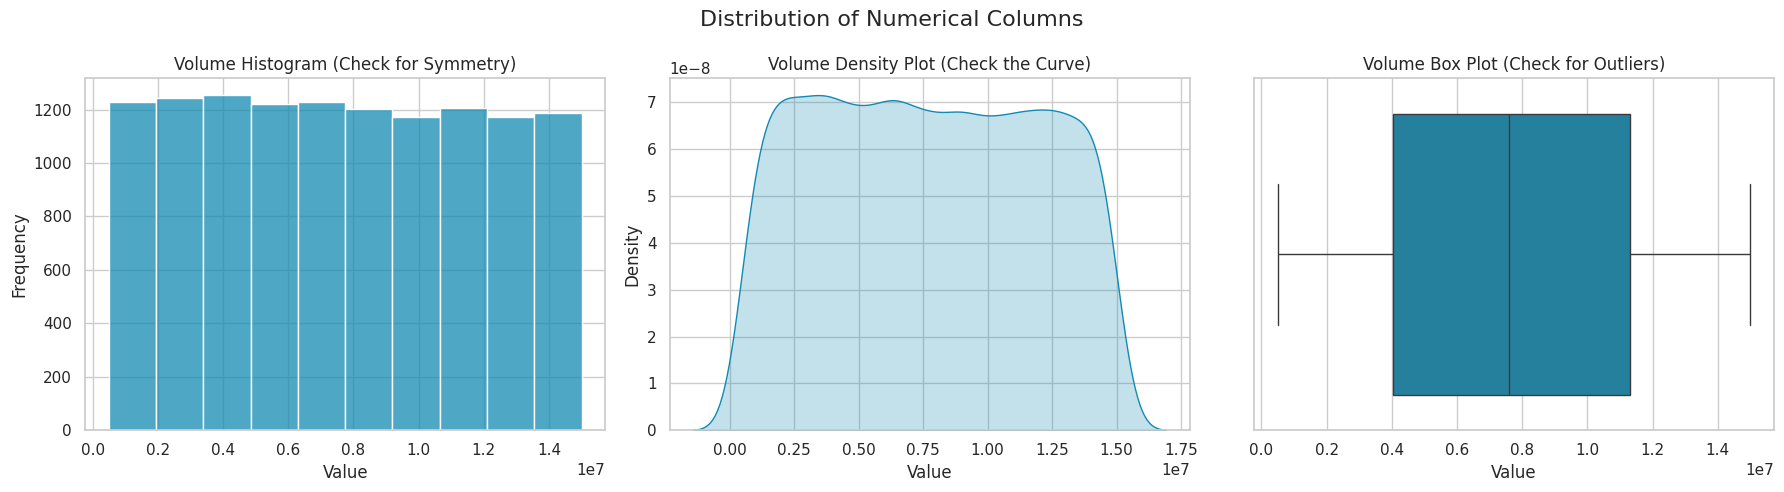

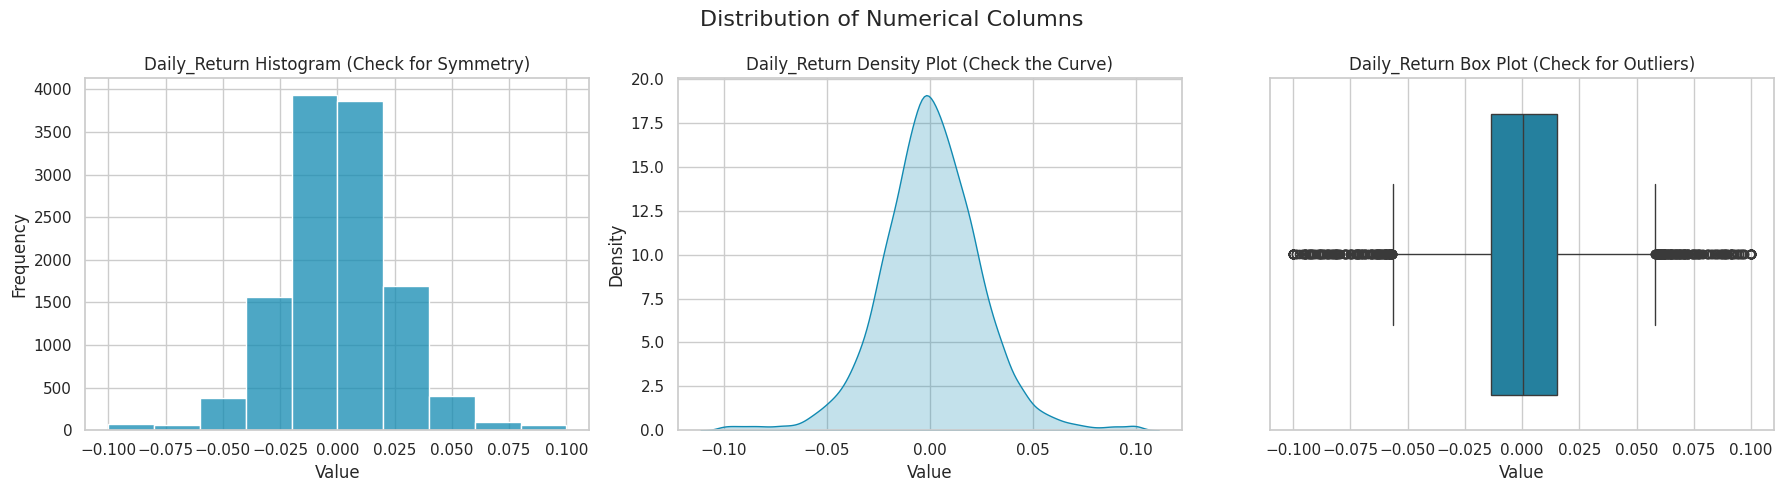

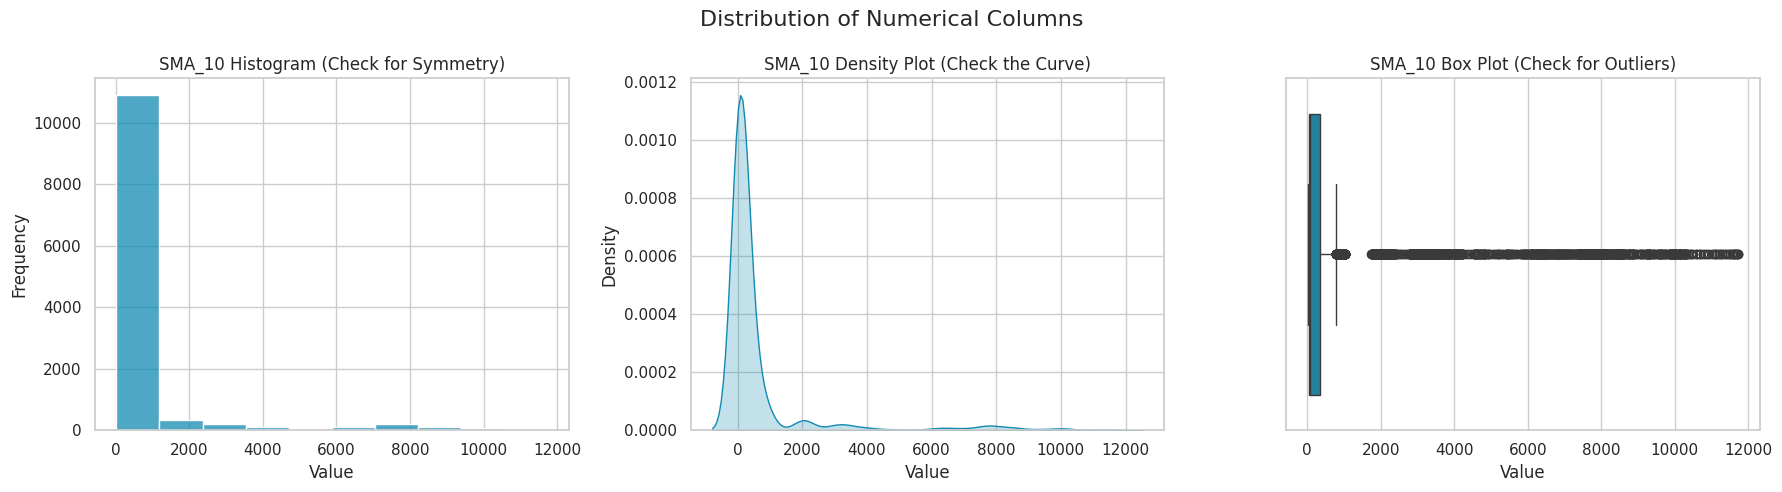

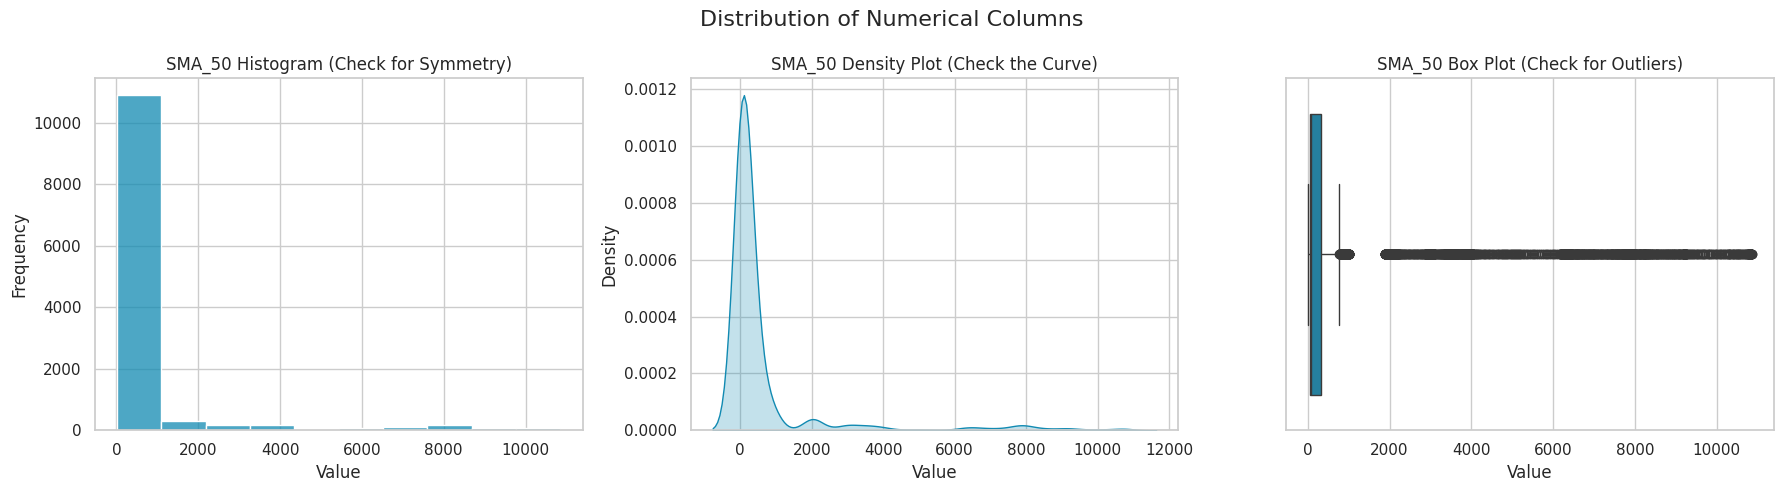

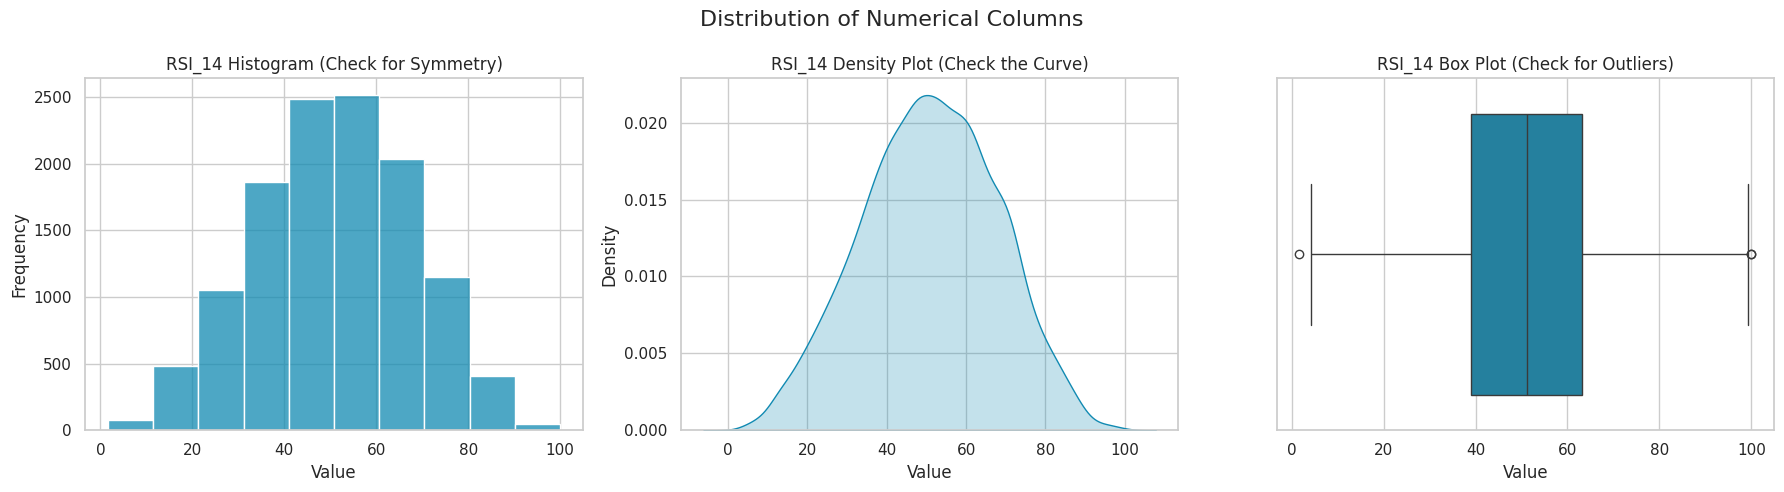

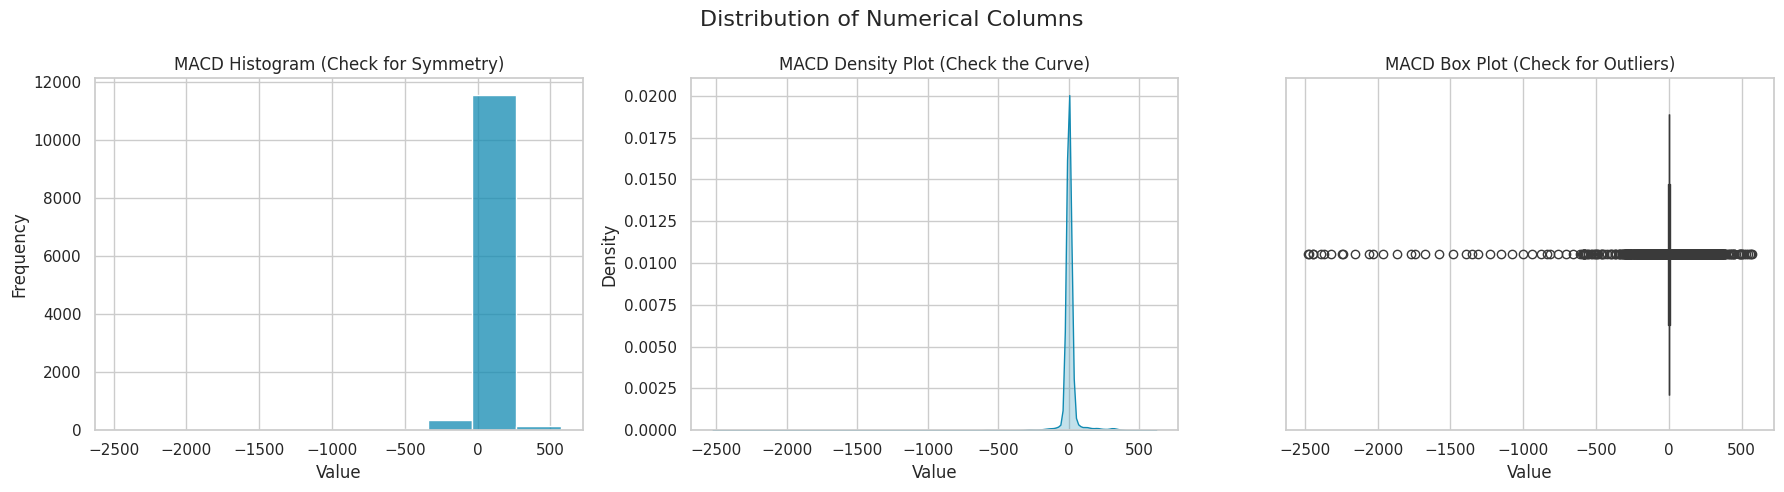

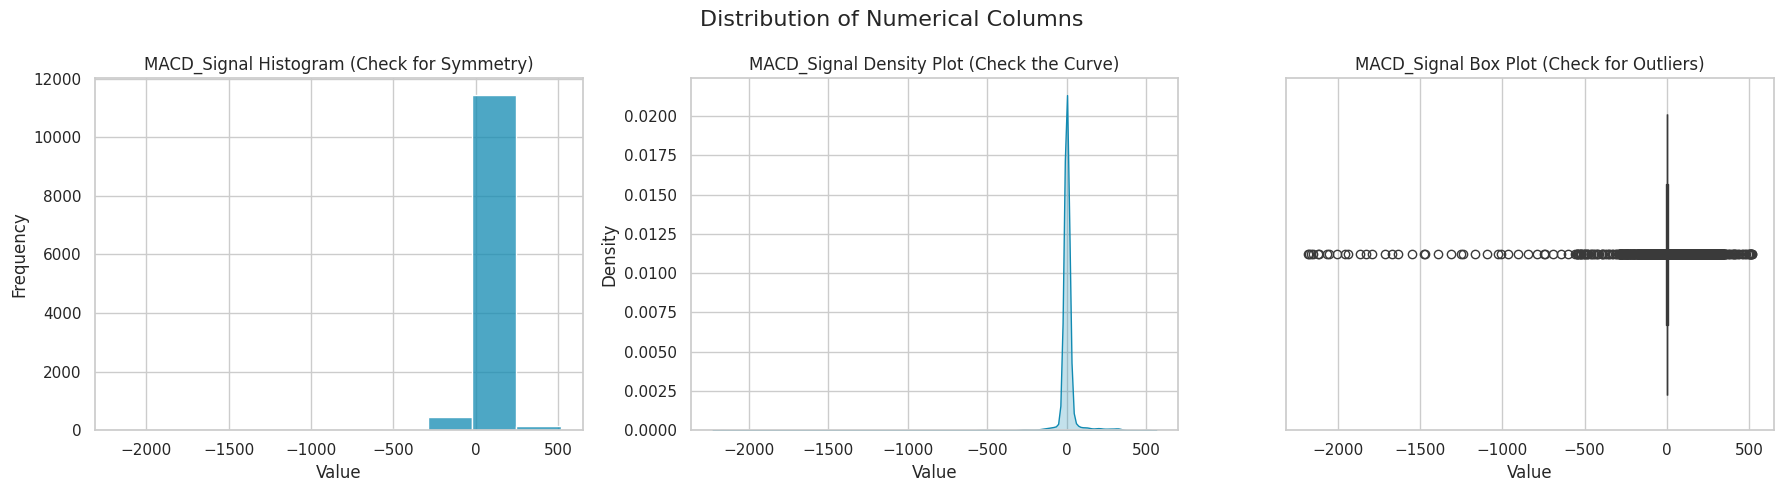

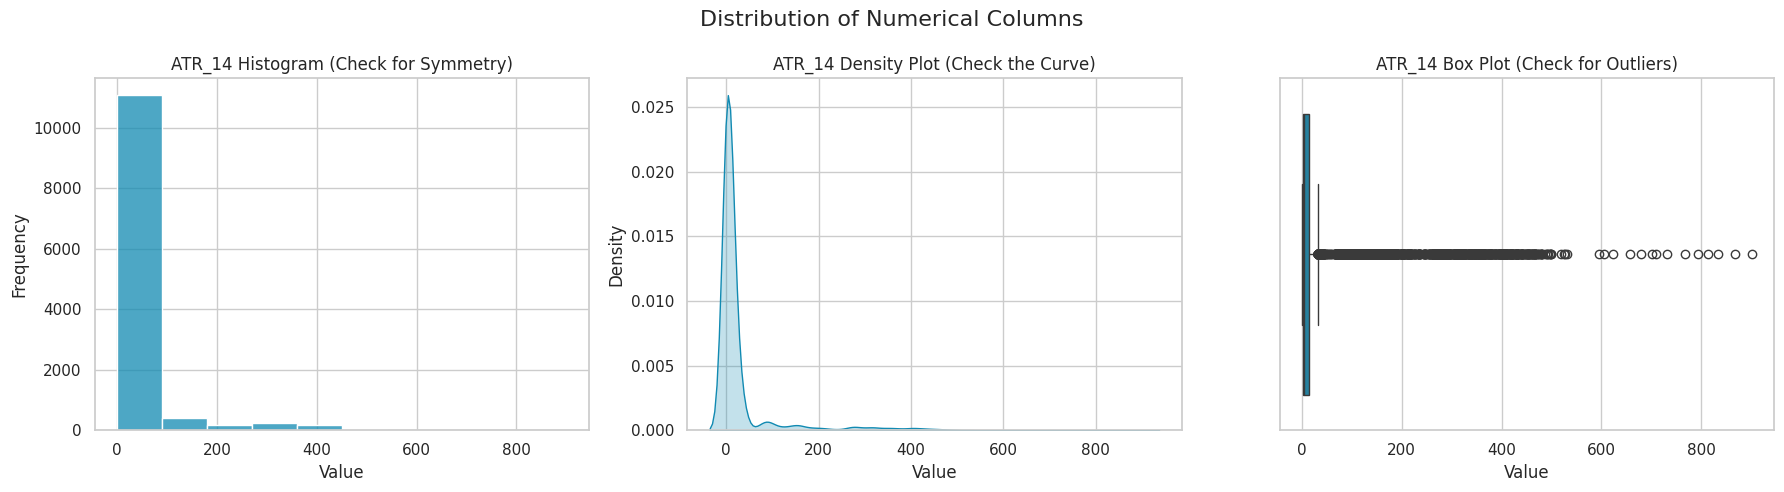

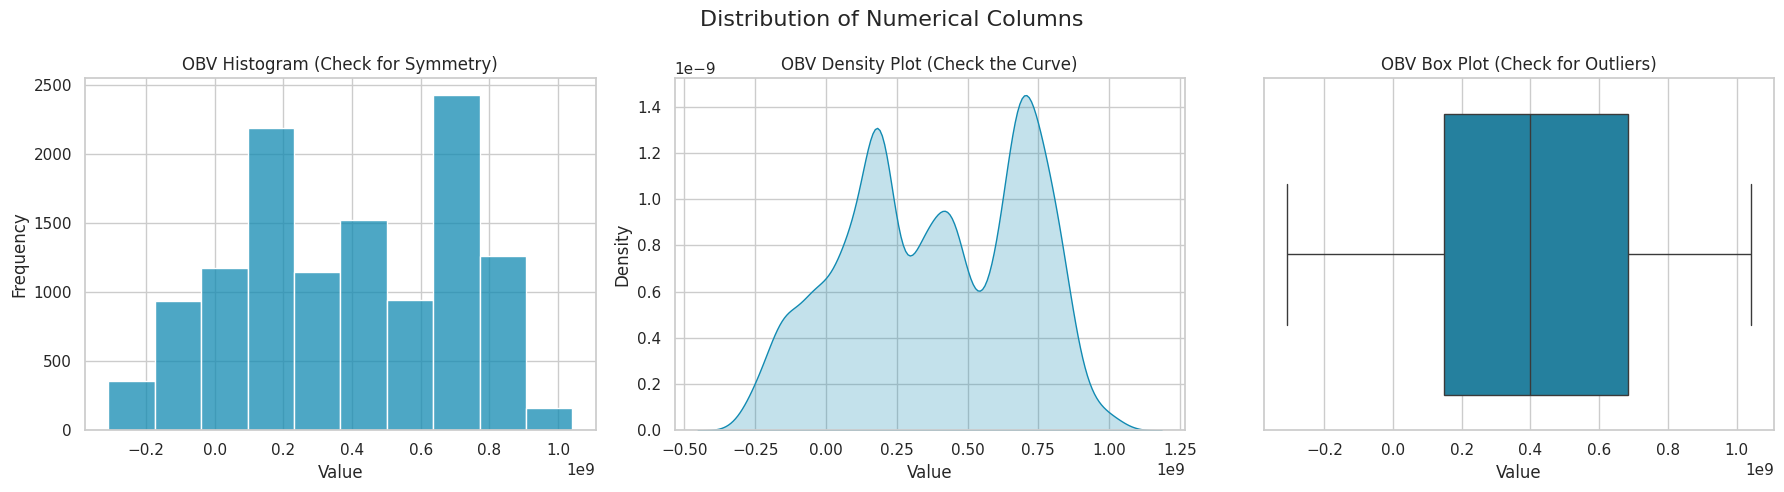

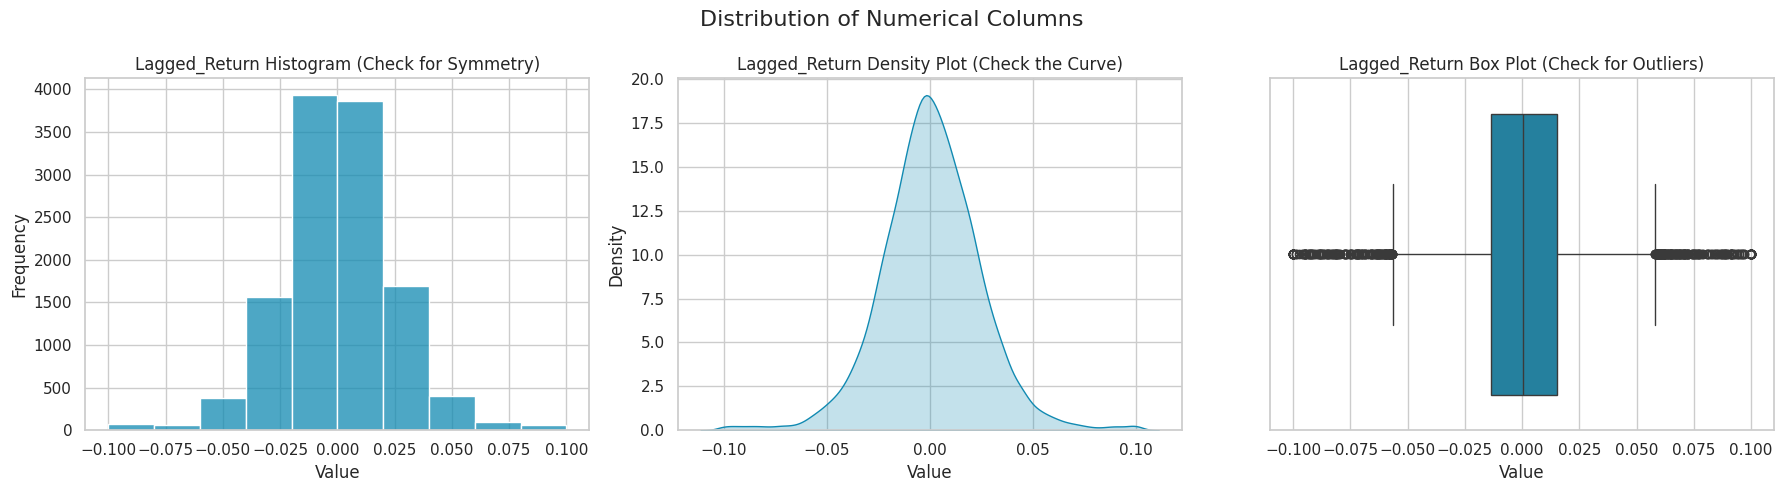

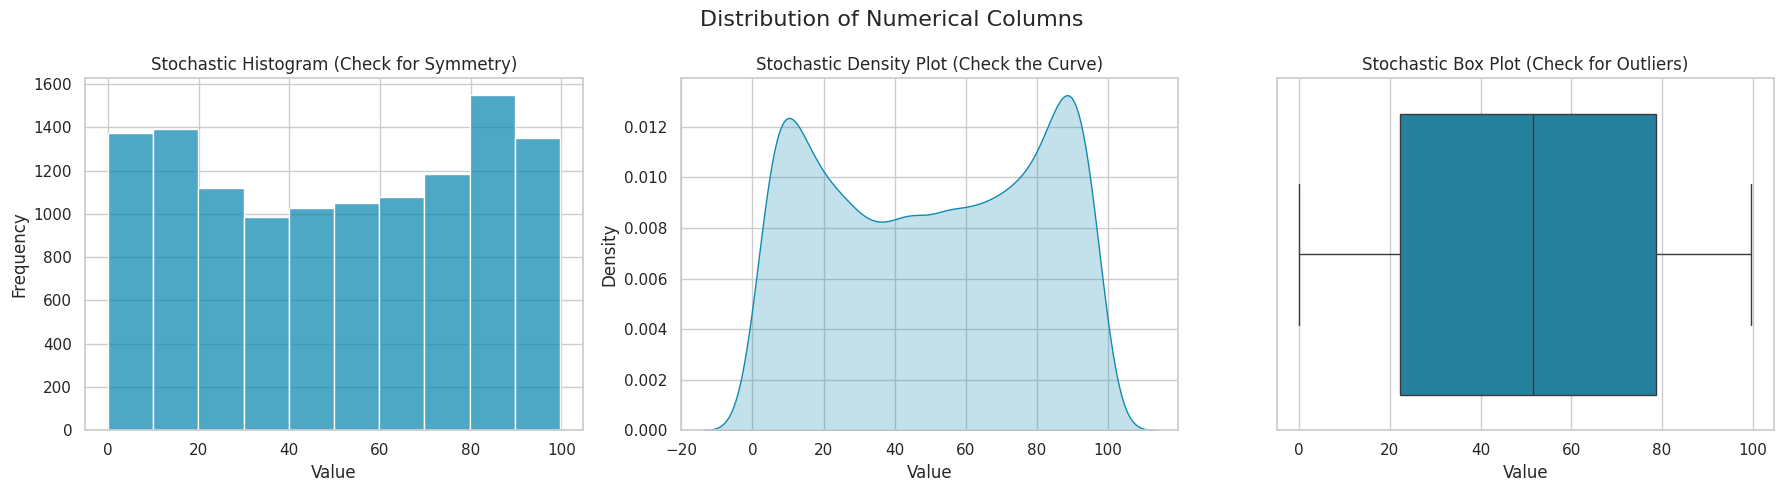

In [ ]:
# plots to check for outliers after inputation of MICE
train_numeric_features = train_df_imputer.select_dtypes(
    include=['int64', 'float64']).columns.drop('Target')

sns.set_theme(style="whitegrid")
primary_color = "#118ab2"

for i in train_numeric_features:
    # create a figure with 3 subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Distribution of Numerical Columns', fontsize=16)

    # histogram
    sns.histplot(train_df_imputer[i], bins=10, color=primary_color, ax=axes[0])
    axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')

    # density plot
    sns.kdeplot(train_df_imputer[i], color=primary_color, fill=True, ax=axes[1])
    axes[1].set_title(f'{i} Density Plot (Check the Curve)')
    axes[1].set_xlabel('Value')
    axes[1].set_ylabel('Density')

    # boxplot
    sns.boxplot(x=train_df_imputer[i], color=primary_color, ax=axes[2])
    axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
    axes[2].set_xlabel('Value')

    # display the charts
    plt.tight_layout()
    plt.show()

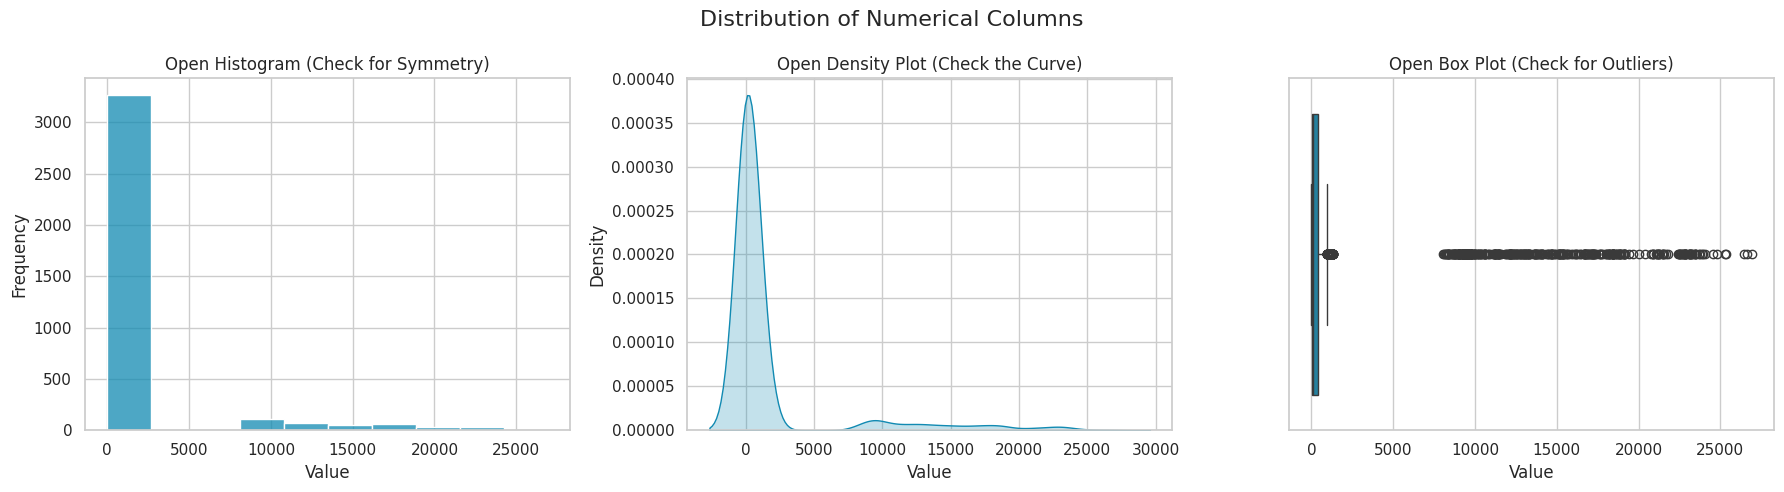

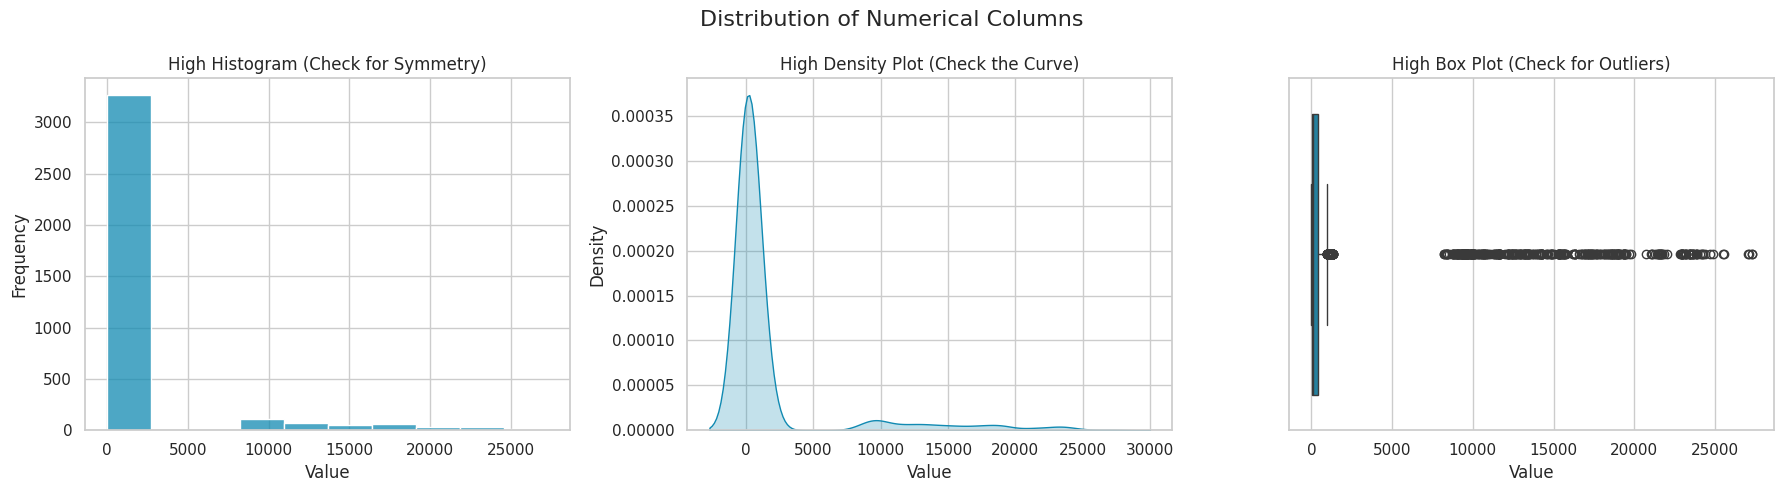

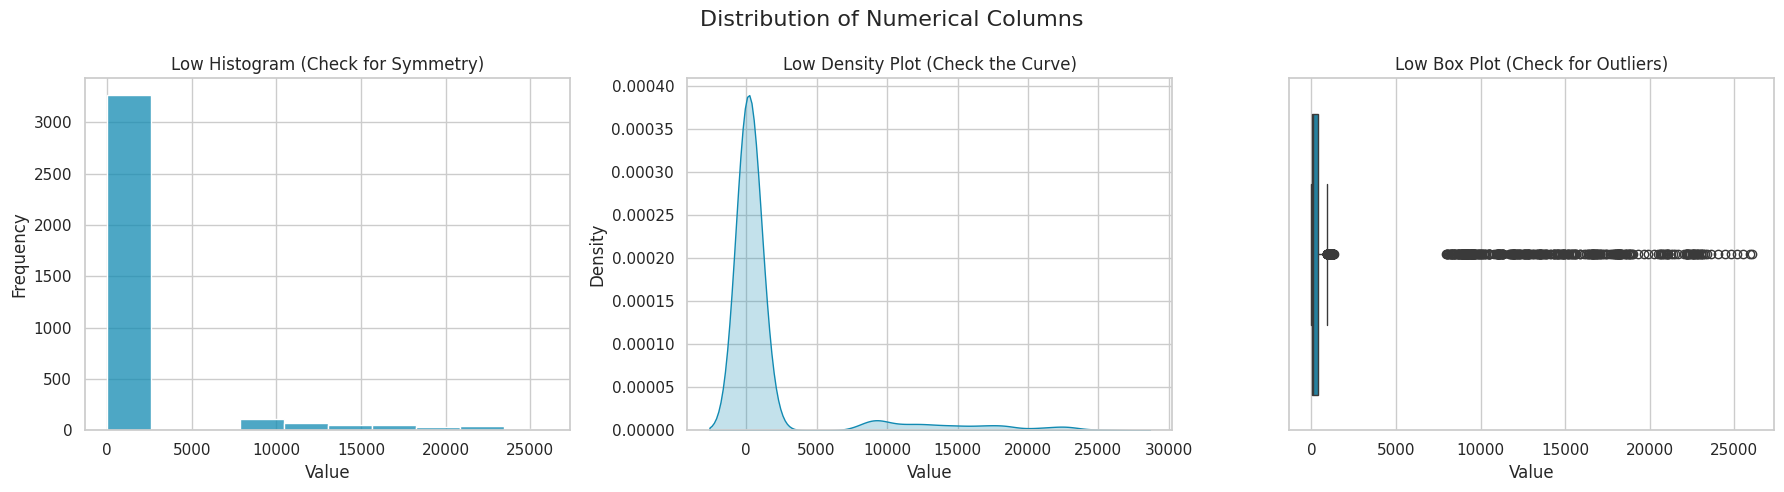

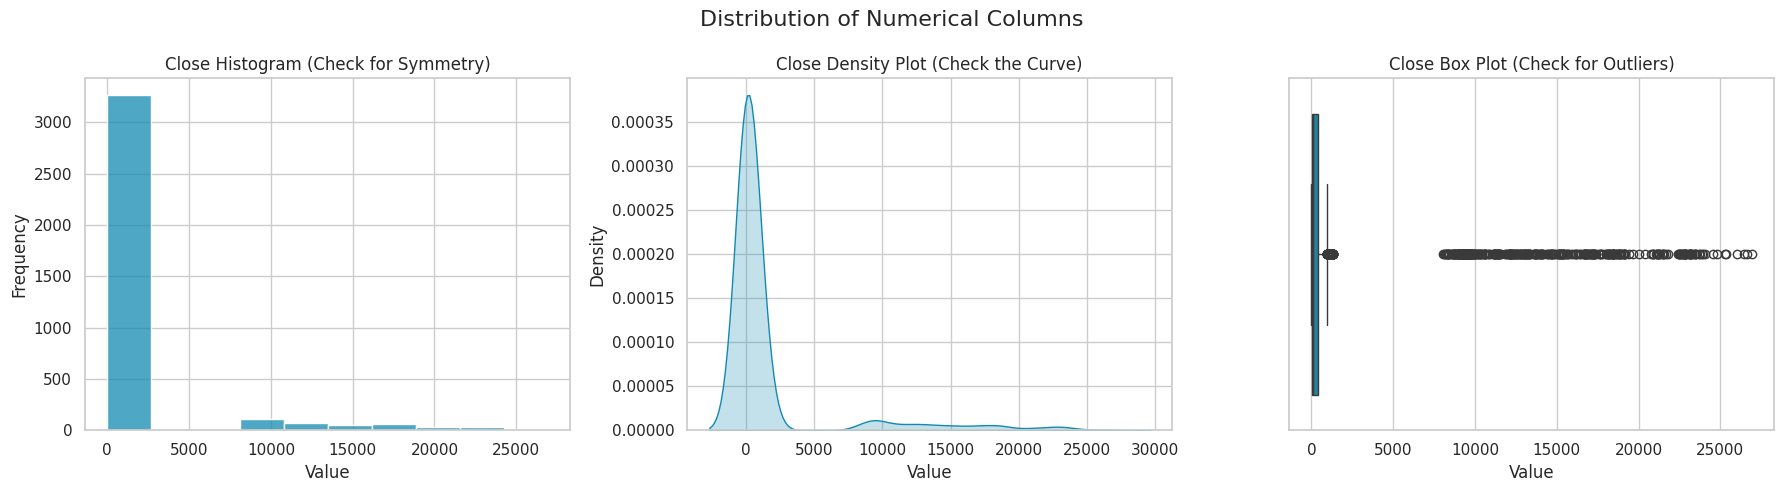

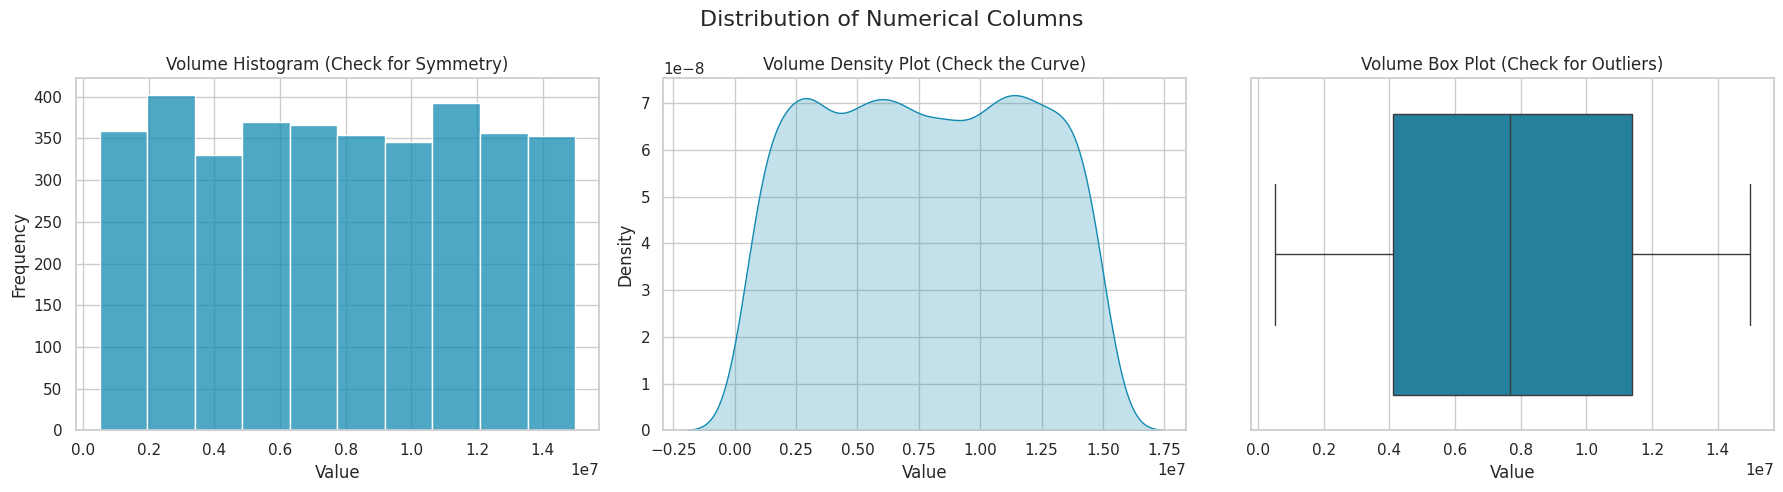

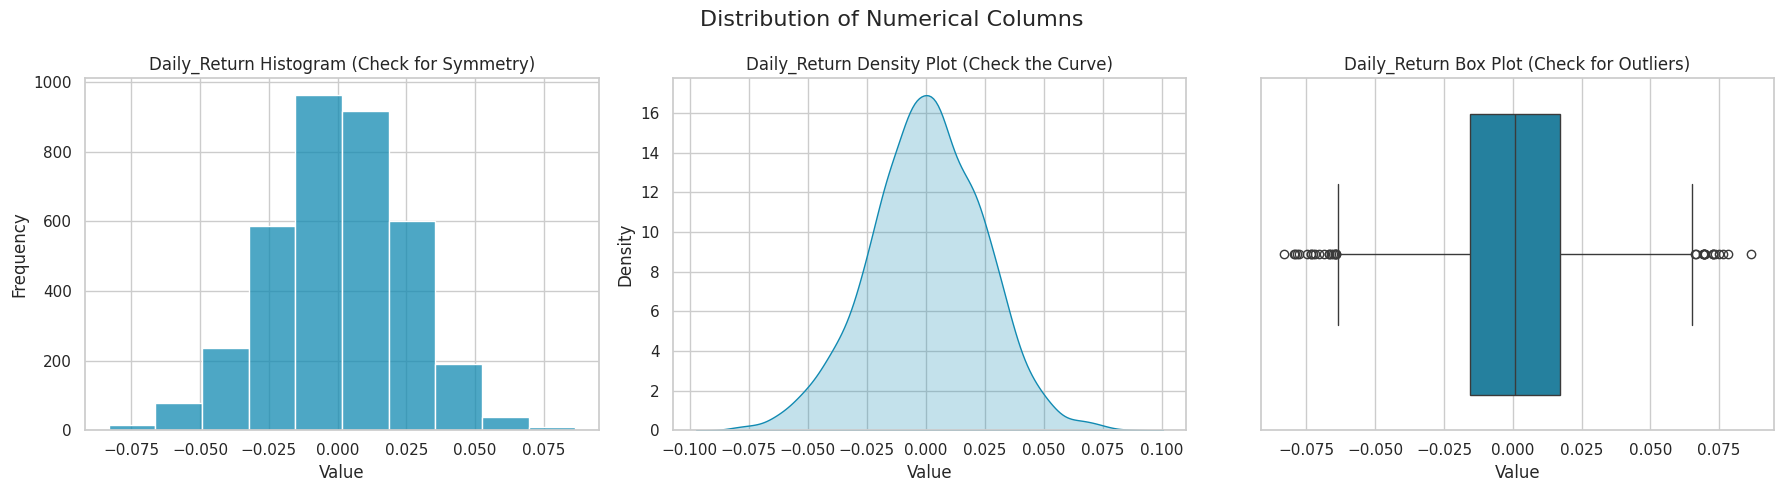

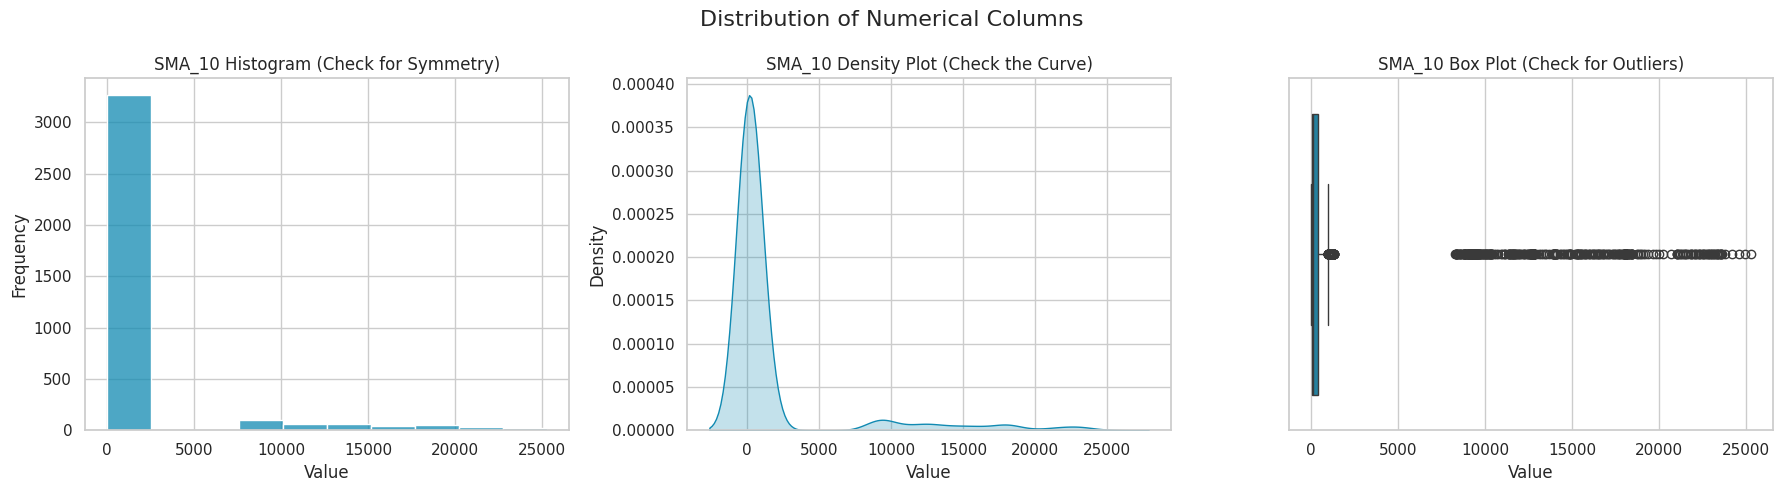

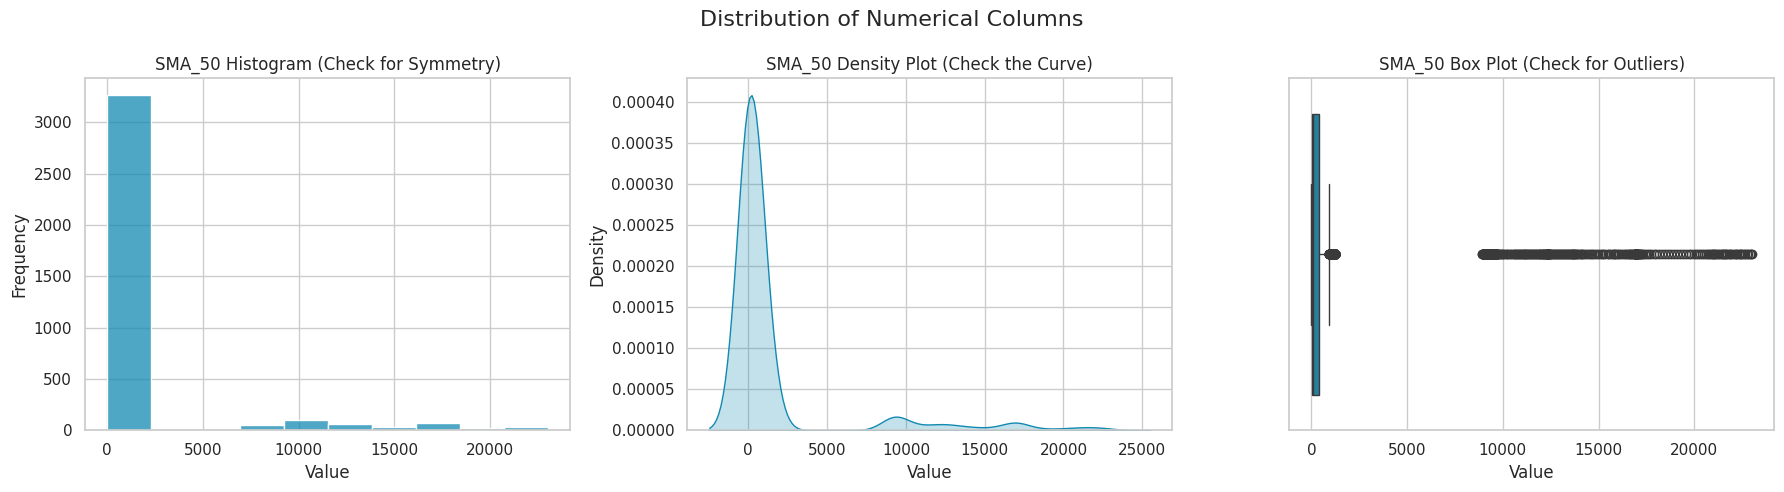

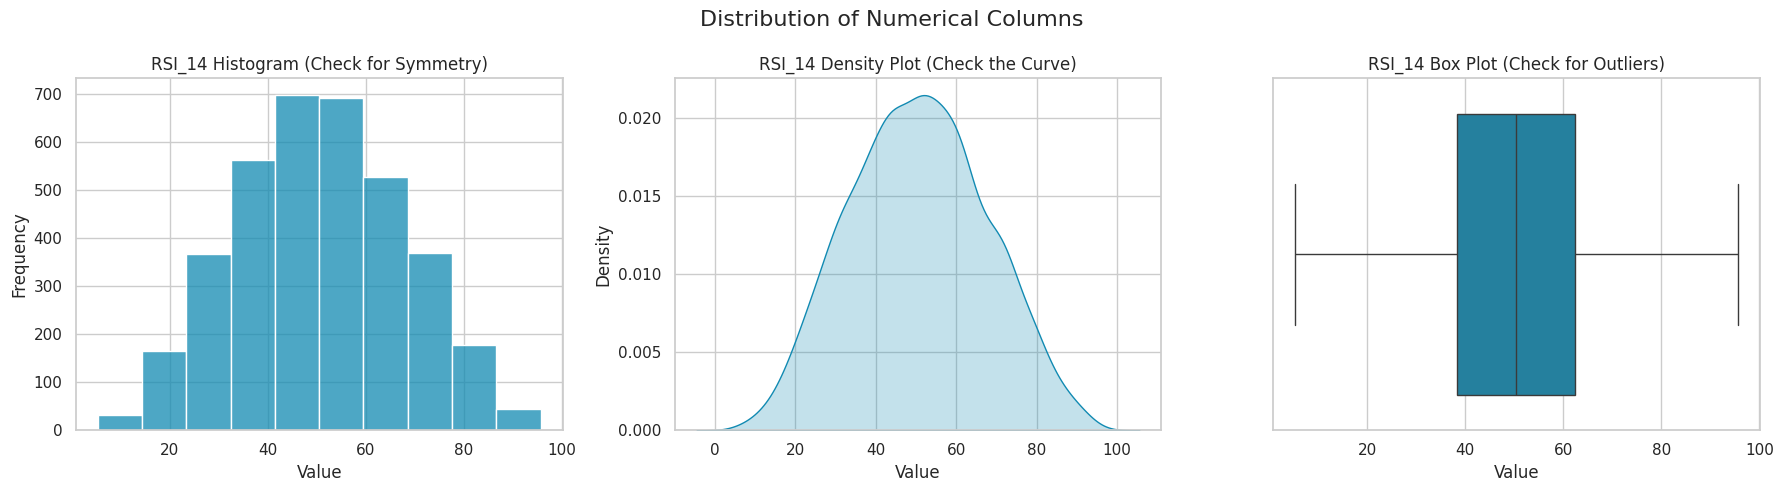

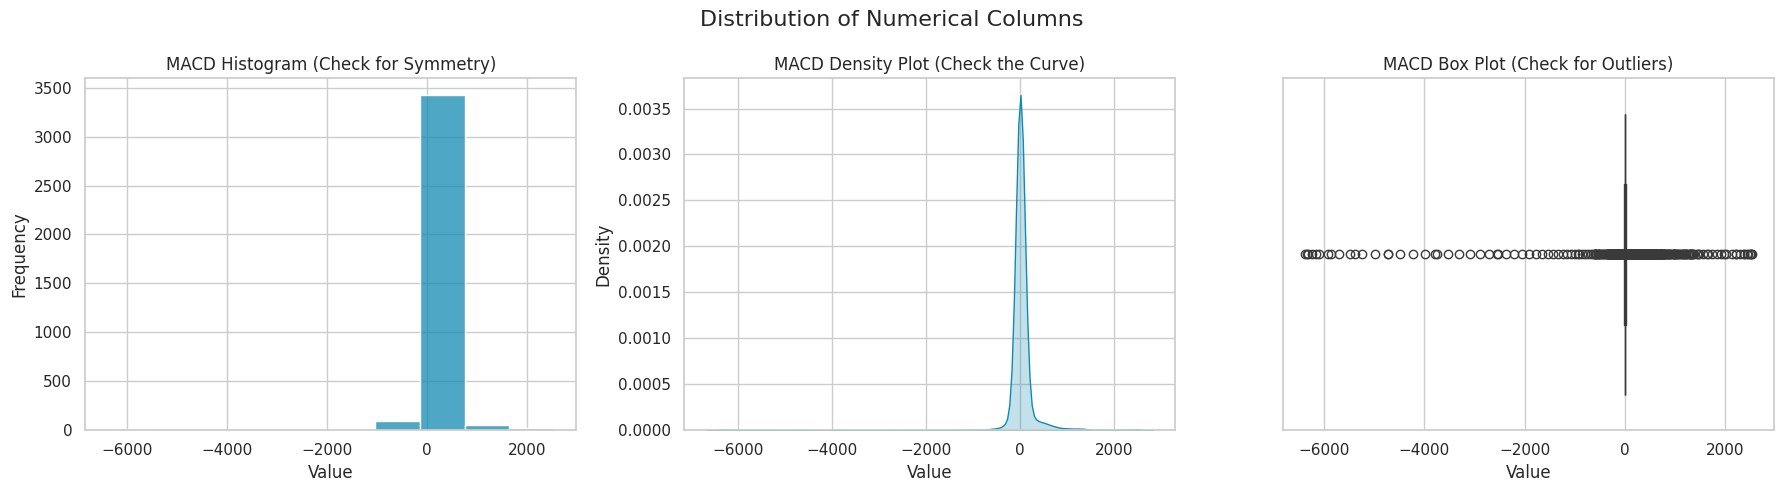

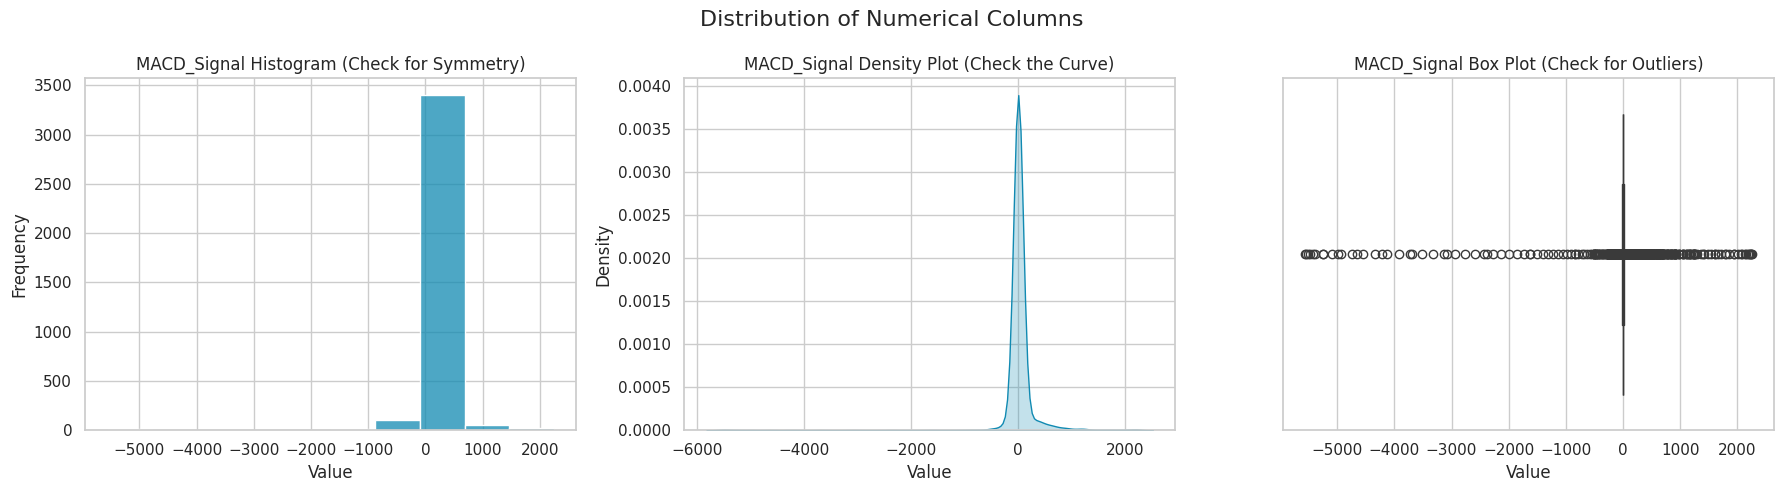

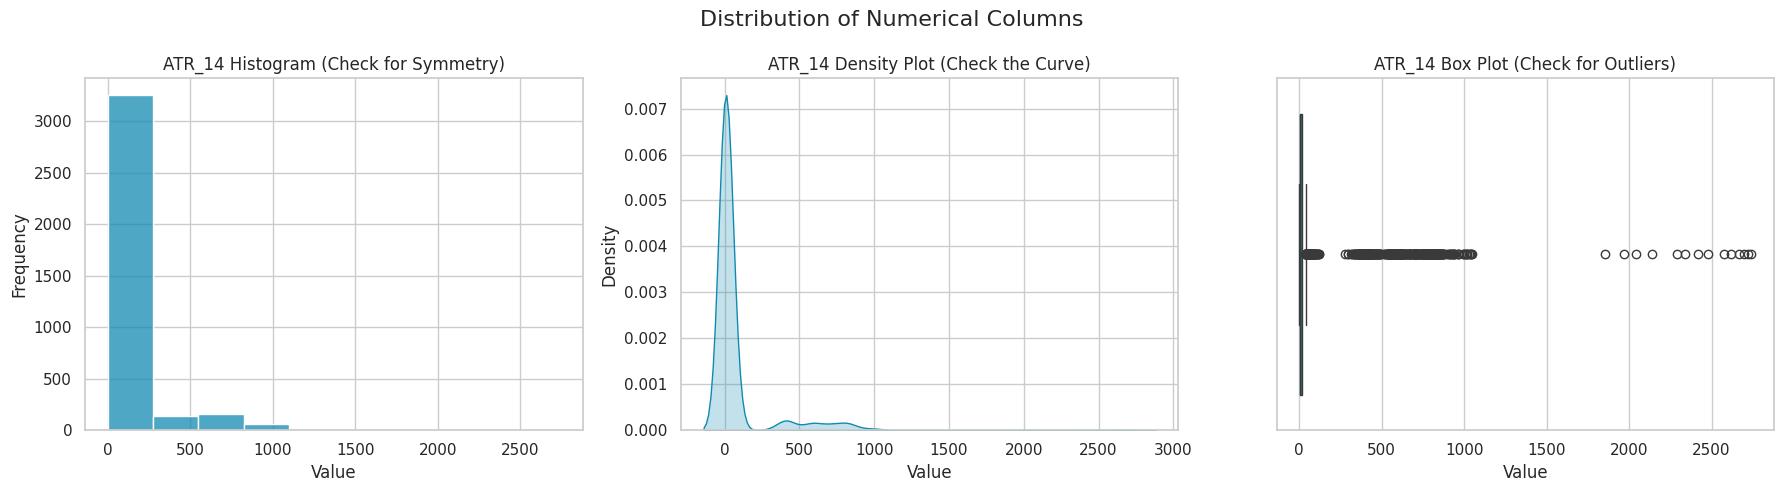

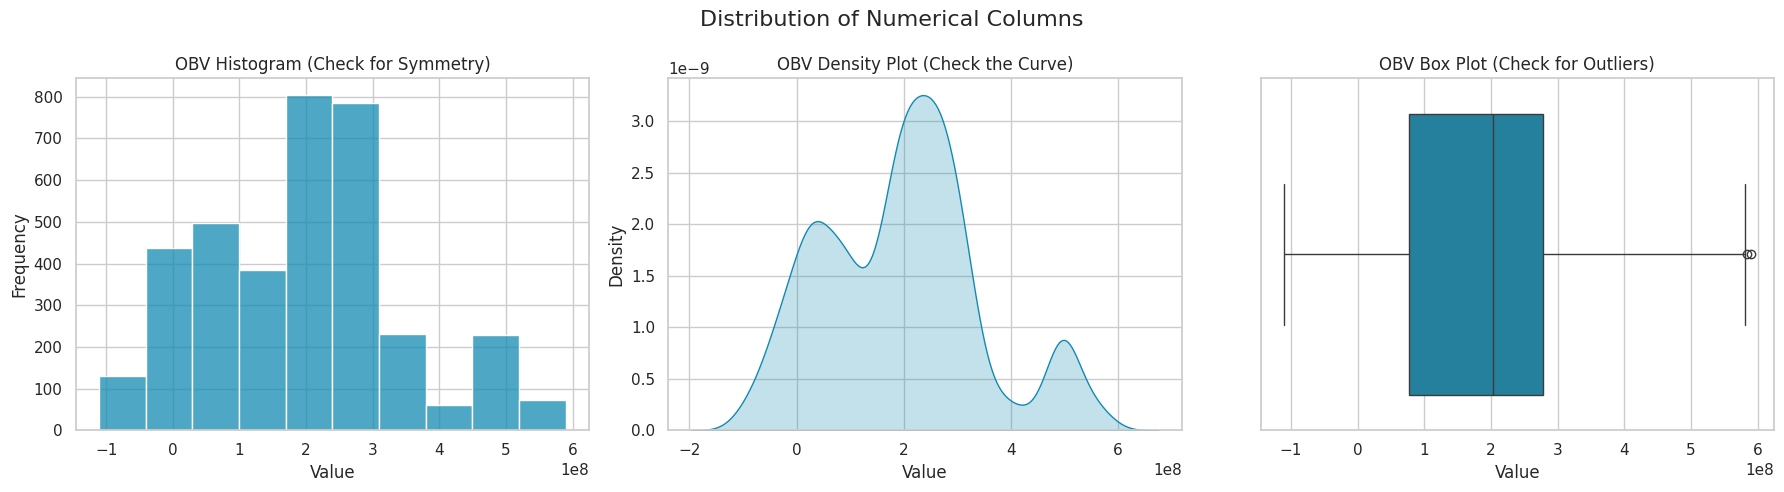

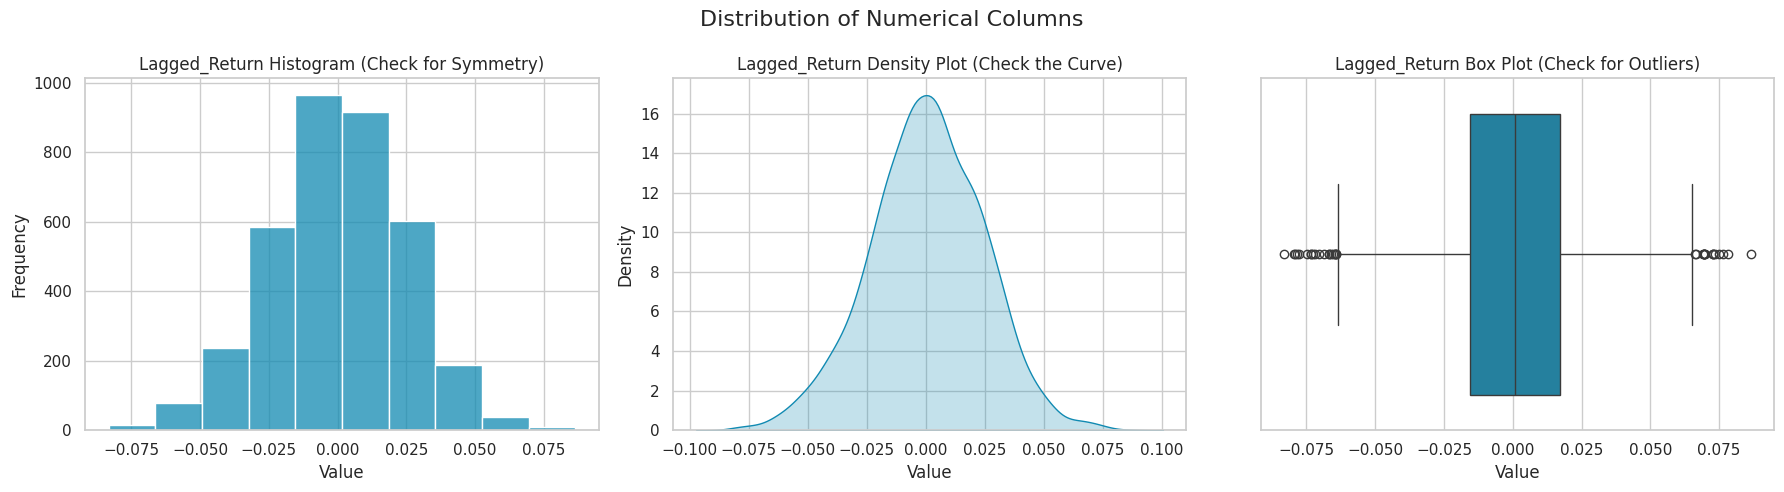

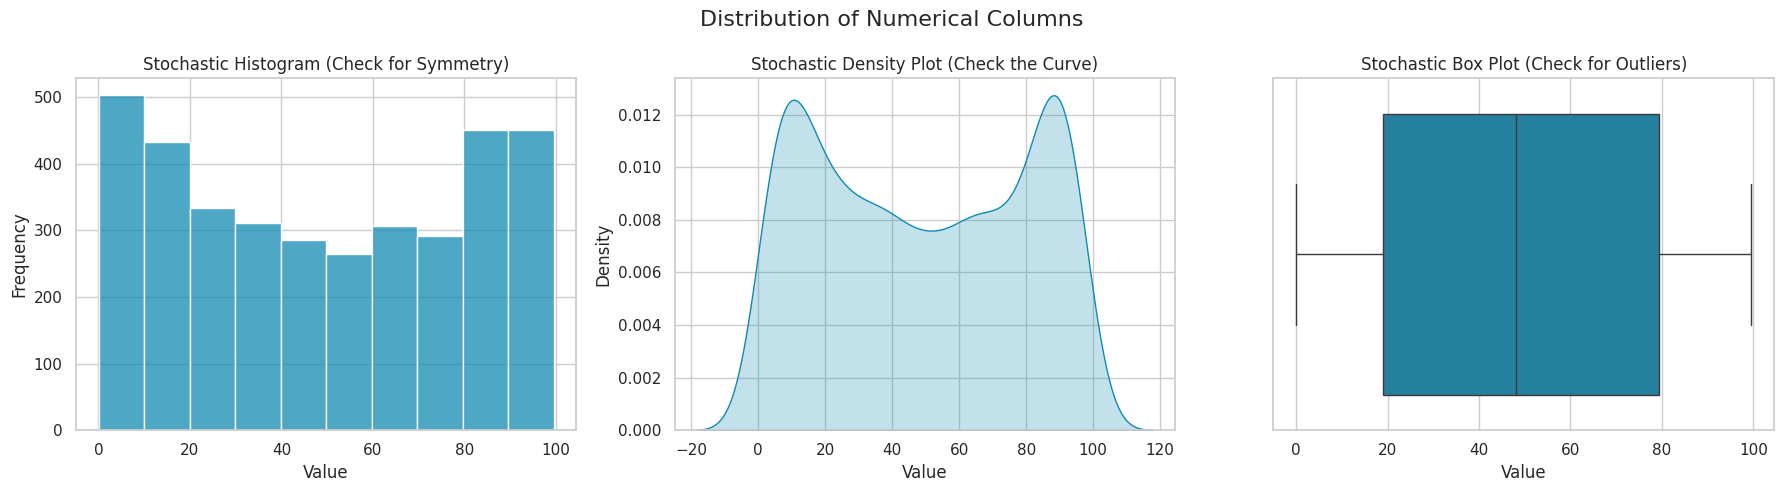

In [ ]:
# plots to check for outliers after inputation of MICE
test_numeric_features = test_df_imputer.select_dtypes(
    include=['int64', 'float64']).columns

sns.set_theme(style="whitegrid")
primary_color = "#118ab2"

for i in test_numeric_features:
    # create a figure with 3 subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Distribution of Numerical Columns', fontsize=16)

    # histogram
    sns.histplot(test_df_imputer[i], bins=10, color=primary_color, ax=axes[0])
    axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')

    # density plot
    sns.kdeplot(test_df_imputer[i], color=primary_color, fill=True, ax=axes[1])
    axes[1].set_title(f'{i} Density Plot (Check the Curve)')
    axes[1].set_xlabel('Value')
    axes[1].set_ylabel('Density')

    # boxplot
    sns.boxplot(x=test_df_imputer[i], color=primary_color, ax=axes[2])
    axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
    axes[2].set_xlabel('Value')

    # display the charts
    plt.tight_layout()
    plt.show()

In [ ]:
train_df_imputer.head()

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,...,Target,Year,Month,Day,MACD,MACD_Signal,ATR_14,OBV,Lagged_Return,Stochastic
0,AFRIBANK,AfriBank Holdings Plc,Banking,30.17,30.37,29.31,29.86,3760802,-0.01,28.59,...,0,2021,3,11,0.00,0.00,28.69,0.00,0.00,50.47
1,AFRIBANK,AfriBank Holdings Plc,Banking,29.86,30.35,29.06,29.27,10909971,-0.02,28.76,...,1,2021,3,12,-0.05,-0.01,28.37,"-10,909,971.00",-0.01,45.42
2,AFRIBANK,AfriBank Holdings Plc,Banking,29.27,29.82,28.83,29.53,9405865,0.01,28.96,...,0,2021,3,15,-0.06,-0.02,28.09,"-1,504,106.00",-0.02,40.99
3,AFRIBANK,AfriBank Holdings Plc,Banking,29.53,30.12,28.89,29.08,5090778,-0.02,29.13,...,0,2021,3,16,-0.11,-0.04,28.94,"-6,594,884.00",0.01,54.43
4,AFRIBANK,AfriBank Holdings Plc,Banking,29.08,29.18,28.73,28.93,10189065,-0.01,29.27,...,1,2021,3,17,-0.16,-0.06,28.21,"-16,783,949.00",-0.02,42.97


In [ ]:
test_df_imputer.head()

,Ticker,Company,Sector,Open,High,Low,Close,Volume,Daily_Return,SMA_10,...,RSI_14,Year,Month,Day,MACD,MACD_Signal,ATR_14,OBV,Lagged_Return,Stochastic
0,AFRIBANK,AfriBank Holdings Plc,Banking,143.13,147.18,141.30,144.98,2734489,0.01,143.84,...,55.65,2025,10,31,0.00,0.00,80.10,0.00,0.00,48.88
1,AFRIBANK,AfriBank Holdings Plc,Banking,144.98,145.68,144.30,144.75,12933495,-0.00,143.81,...,53.13,2025,11,3,-0.02,-0.00,80.10,"-12,933,495.00",0.01,48.88
2,AFRIBANK,AfriBank Holdings Plc,Banking,144.75,146.73,141.60,142.03,14453367,-0.02,143.46,...,33.34,2025,11,4,-0.25,-0.05,80.10,"-27,386,862.00",-0.00,48.88
3,AFRIBANK,AfriBank Holdings Plc,Banking,142.03,144.44,140.09,140.91,9680351,-0.01,143.02,...,32.19,2025,11,5,-0.52,-0.15,80.10,"-37,067,213.00",-0.02,48.88
4,AFRIBANK,AfriBank Holdings Plc,Banking,140.91,142.49,140.51,141.20,5221339,0.00,143.02,...,26.63,2025,11,6,-0.70,-0.26,80.10,"-31,845,874.00",-0.01,48.88


In [ ]:
# Custom Outlier Capper
class OutlierCapper(BaseEstimator, TransformerMixin):

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = pd.DataFrame(X)

        Q1 = X.quantile(0.25)
        Q3 = X.quantile(0.75)

        IQR = Q3 - Q1

        self.lower_bound_ = Q1 - self.factor * IQR
        self.upper_bound_ = Q3 + self.factor * IQR

        return self


    def transform(self, X):
        X = pd.DataFrame(X).copy()

        X = X.clip(lower=self.lower_bound_,upper=self.upper_bound_, axis=1)

        return X.values

# separate target
target_col = "Target"

X = train_df_imputer.drop( columns=[target_col], errors='ignore')

y = train_df_imputer[target_col]

# automatically detect columns

numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Daily_Return", "SMA_10", "SMA_50", "RSI_14","Year","Month","Day",
"MACD", "MACD_Signal", "ATR_14", "OBV", "Lagged_Return", "Stochastic"]
categorical_cols = ["Ticker","Company","Sector"]


print("Number of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

# train validation split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

# Outlier capping

capper = OutlierCapper(factor=1.5)
X_train_num_capped = capper.fit_transform( X_train_sub[numeric_cols])
X_val_num_capped = capper.transform( X_val[numeric_cols])

# Scaling

scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform( X_train_num_capped)
X_val_num_scaled = scaler.transform( X_val_num_capped)

# convert back to dataframe

X_train_num_scaled = pd.DataFrame( X_train_num_scaled, columns=numeric_cols, index=X_train_sub.index)

X_val_num_scaled = pd.DataFrame(X_val_num_scaled, columns=numeric_cols,index=X_val.index)


# one Hot Encoding

if len(categorical_cols) > 0:
   encoder = OneHotEncoder( handle_unknown="ignore", sparse_output=False)
   X_train_cat_encoded = encoder.fit_transform(X_train_sub[categorical_cols])
   X_val_cat_encoded = encoder.transform( X_val[categorical_cols])

   ohe_cols = encoder.get_feature_names_out(categorical_cols)

   X_train_cat_encoded = pd.DataFrame( X_train_cat_encoded, columns=ohe_cols, index=X_train_sub.index )
   X_val_cat_encoded = pd.DataFrame( X_val_cat_encoded, columns=ohe_cols,index=X_val.index )
else:
   X_train_cat_encoded = pd.DataFrame(index=X_train_sub.index )
   X_val_cat_encoded = pd.DataFrame(index=X_val.index)

# Combine processed features
X_train_final = pd.concat([X_train_num_scaled,X_train_cat_encoded], axis=1)
X_val_final = pd.concat([X_val_num_scaled, X_val_cat_encoded],axis=1)

# final checks

print("\nPipeline completed successfully")
print("Training features:", X_train_final.shape)
print("Validation features:", X_val_final.shape)
print("Training target:", y_train_sub.shape)
print("Validation target:", y_val.shape)

Number of numerical columns: 18
Number of categorical columns: 3

Pipeline completed successfully
Training features: (9688, 43)
Validation features: (2422, 43)
Training target: (9688,)
Validation target: (2422,)


In [ ]:
X_train_final.head()

,Open,High,Low,Close,Volume,Daily_Return,SMA_10,SMA_50,RSI_14,Year,...,Company_GT Capital Holdings Plc,Company_MTN Nigeria Communications Plc,Company_Nigerian Energy Resources Plc,Company_Unilever Nigeria Plc,Company_Zenith Capital Bank Plc,Sector_Banking,Sector_Consumer Goods,Sector_Industrial Goods,Sector_Oil & Gas,Sector_Telecommunications
11200,-0.67,-0.66,-0.67,-0.66,-1.22,1.78,-0.66,-0.67,0.82,-0.74,...,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00
6736,2.02,2.13,2.05,2.13,1.58,2.33,1.99,1.77,1.80,-0.00,...,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
6163,0.26,0.25,0.27,0.25,0.91,-0.41,0.35,0.46,-2.06,-1.47,...,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
10367,-0.67,-0.67,-0.67,-0.67,0.72,1.32,-0.67,-0.64,-0.14,-0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
8642,-0.57,-0.57,-0.56,-0.56,-0.33,0.88,-0.56,-0.56,0.27,-1.47,...,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00


In [ ]:
models = {
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)
}

models_results = []
for name, model in models.items():          # <-- loop over models, not models_results
    model.fit(X_train_final, y_train_sub)
    preds = model.predict(X_val_final)
    probs = model.predict_proba(X_val_final)[:, 1]

    models_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, preds),
        'Precision': precision_score(y_val, preds),
        'Recall': recall_score(y_val, preds),
        'F1 Score': f1_score(y_val, preds),
        'ROC-AUC': roc_auc_score(y_val, probs)
    })

models_df = pd.DataFrame(models_results).set_index('Model')
print("Models Performance")
print("-" * 40)
print(models_df.round(4))

Models Performance
----------------------------------------
          Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                   
XGBoost       0.49       0.50    0.50      0.50     0.50
LightGBM      0.51       0.52    0.55      0.53     0.52
CatBoost      0.51       0.51    0.53      0.52     0.52


In [ ]:
from scipy.stats import randint, uniform
# XGBoost parameter tuning
xgb_param_dist = {
    'n_estimators': randint(200, 501),
    'max_depth': randint(2, 7),
    'learning_rate': uniform(0.01, 0.09),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'gamma': uniform(0, 0.5),
    'reg_alpha': uniform(0, 1),
    'reg_lambda': uniform(0, 1)
}


xgb_search = RandomizedSearchCV(
    XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric='logloss'
    ),
    param_distributions=xgb_param_dist,
    n_iter=100,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_final, y_train_sub)

best_xgb = xgb_search.best_estimator_



# LightGBM parameter tuning

lgbm_param_dist = {
    'n_estimators': randint(200, 501),
    'max_depth': randint(3, 9),
    'learning_rate': uniform(0.01, 0.09),
    'num_leaves': randint(10, 50),
    'min_child_samples': randint(20, 100),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': uniform(0, 1),
    'reg_lambda': uniform(0, 1)
}


lgbm_search = RandomizedSearchCV(
    LGBMClassifier(
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    param_distributions=lgbm_param_dist,
    n_iter=100,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

lgbm_search.fit(X_train_final, y_train_sub)

best_lgbm = lgbm_search.best_estimator_



# CatBoost parameter tuning

cat_param_dist = {
    'iterations': randint(200, 601),
    'depth': randint(3, 9),
    'learning_rate': uniform(0.01, 0.09),
    'l2_leaf_reg': randint(1, 10),
    'random_strength': uniform(0, 2),
    'bagging_temperature': uniform(0, 1),
    'auto_class_weights': ['Balanced']
}


cat_search = RandomizedSearchCV(
    CatBoostClassifier(
        random_state=RANDOM_STATE,
        verbose=0
    ),
    param_distributions=cat_param_dist,
    n_iter=100,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

cat_search.fit(X_train_final, y_train_sub)

best_cat = cat_search.best_estimator_



# Compare tuned models

tuned_models = {
    'Tuned XGBoost': best_xgb,
    'Tuned LightGBM': best_lgbm,
    'Tuned CatBoost': best_cat
}


tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_val_final)

    probabilities = model.predict_proba(X_val_final)[:, 1]

    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1 Score': f1_score(y_val, predictions),
        'ROC-AUC': roc_auc_score(y_val, probabilities)
    })


tuned_df = pd.DataFrame(tuned_results).set_index('Model')


print("Tuned Models Performance")
print(tuned_df.round(4))


print("\nBest XGBoost Parameters")
print(xgb_search.best_params_)

print("\nBest LightGBM Parameters")
print(lgbm_search.best_params_)

print("\nBest CatBoost Parameters")
print(cat_search.best_params_)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Tuned Models Performance
                Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                         
Tuned XGBoost       0.50       0.50    0.52      0.51     0.51
Tuned LightGBM      0.51       0.51    0.53      0.52     0.51
Tuned CatBoost      0.51       0.52    0.51      0.51     0.52

Best XGBoost Parameters
{'colsample_bytree': np.float64(0.7696522685209544), 'gamma': np.float64(0.3682221178123614), 'learning_rate': np.float64(0.09409303132921133), 'max_depth': 4, 'min_child_weight': 7, 'n_estimators': 456, 'reg_alpha': np.float64(0.11323804584075525), 'reg_lambda': np.float64(0.9848411989623346), 'subsample': np.float64(0.9355592345783736)}

Best LightGBM Parameters
{'colsample_bytree': np.float64(0.749816047538945), 'learning_rate': np.float64

In [ ]:
def create_theory_features(df):

    df = df.copy()
    #theory one
    # mean reversion (ornstein-uhlenbeck)
    # how many standard deviations price sits away from its 20-day mean
    # a large |z-score| implies "pressure" pulling price back toward equilibrium
    sma20 = df["Close"].rolling(window=20).mean()
    std20 = df["Close"].rolling(window=20).std()
    df["MeanReversion_Z"] = (df["Close"] - sma20) / std20
    #theory two
    # amihud illiquidity (market microstructure)
    # price impact per unit of money traded: big moves on thin volume = illiquid = fragile
    # analogous to low permeability restricting flow through the reservoir
    dollar_volume = df["Close"] * df["Volume"]
    df["Amihud_Illiquidity"] = (df["Daily_Return"].abs() / dollar_volume).replace(
        [np.inf, -np.inf], np.nan
    )
    #theory three
    #  hurst-style persistence (trending vs mean-reverting regime)
    # lag-1 autocorrelation of returns over a rolling window
    # positive = trending/persistent (like laminar flow), negative = mean-reverting (turbulent)
    df["Return_Autocorr_10"] = (
        df["Daily_Return"].rolling(window=10).apply(
            lambda x: pd.Series(x).autocorr(lag=1), raw=False
        )
    )
    # theory four
    #  volatility clustering (garch intuition)
    # ratio of short-term to long-term realized volatility
    # ratio > 1 means we're in an active/turbulent regime; volatility tends to cluster, not appear randomly
    vol_short = df["Daily_Return"].rolling(window=5).std()
    vol_long = df["Daily_Return"].rolling(window=20).std()
    df["Volatility_Ratio"] = vol_short / vol_long
    #theory five
    #  turnover ratio (flow rate vs baseline)
    # today's volume relative to its own recent average — detects unusual activity
    avg_volume_20 = df["Volume"].rolling(window=20).mean()
    df["Turnover_Ratio"] = df["Volume"] / avg_volume_20
    #theory six
    #  52-week high anchoring (behavioral finance)
    # how close price is to its trailing 1-year high
    # investors anchor to this level psychologically, creating resistance/breakout behavior
    rolling_high_252 = df["Close"].rolling(window=252, min_periods=30).max()
    df["Pct_Of_52wk_High"] = df["Close"] / rolling_high_252

    return df


# apply on top of the first domain-feature block
train_df_theory = create_theory_features(train_df_domain)
test_df_theory = create_theory_features(test_df_domain)

Imputation method comparison using masked observed values:
Method  RMSE
  MICE 24.15
  Mean 26.18
Median 27.18
   KNN 27.18


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


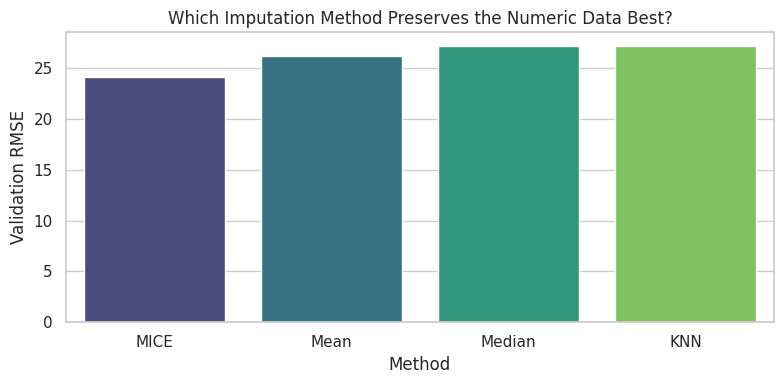

In [ ]:

# select missing numeric column for train
theory_train_numeric_features = train_df_theory.select_dtypes(
    include=['int64', 'float64']
).columns [ train_df_theory.select_dtypes(include=['int64', 'float64']).isnull().any()]


#test_numeric_features = test_df_domain.select_dtypes(
   # include=['int64', 'float64']
#).columns

comparison_source = train_df_theory[theory_train_numeric_features].copy()
observed_positions = np.argwhere(comparison_source.notna().to_numpy())
rng = np.random.default_rng(42)
mask_size = max(1, int(len(observed_positions) * 0.1))
selected_positions = observed_positions[rng.choice(len(observed_positions), size=mask_size, replace=False)]
validation_mask = pd.DataFrame(False, index=comparison_source.index, columns=comparison_source.columns)
for row_idx, col_idx in selected_positions:
    validation_mask.iat[row_idx, col_idx] = True

masked_data = comparison_source.mask(validation_mask)
scaler = StandardScaler()
scaled_masked = pd.DataFrame(
    scaler.fit_transform(masked_data),
    columns=theory_train_numeric_features,
    index=masked_data.index
)

imputer_trials = {
    'Mean': SimpleImputer(strategy='mean'),
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5, weights='distance'),
    'MICE': IterativeImputer(random_state=42, max_iter=20)
}

comparison_rows = []
validation_mask_array = validation_mask.to_numpy()
actual_values = comparison_source.to_numpy()[validation_mask_array]

for method_name, imputer in imputer_trials.items():
    imputed_scaled = pd.DataFrame(
        imputer.fit_transform(scaled_masked),
        columns=theory_train_numeric_features,
        index=scaled_masked.index
    )
    imputed_values = pd.DataFrame(
        scaler.inverse_transform(imputed_scaled),
        columns=theory_train_numeric_features,
        index=scaled_masked.index
    )

    predicted_values = imputed_values.to_numpy()[validation_mask_array]
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    comparison_rows.append({
        'Method': method_name,
        'RMSE': rmse
    })

comparison_results = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
print('Imputation method comparison using masked observed values:')
print(comparison_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_results, x='Method', y='RMSE', hue='Method', palette='viridis', legend=False)
plt.title('Which Imputation Method Preserves the Numeric Data Best?')
plt.xlabel('Method')
plt.ylabel('Validation RMSE')
plt.tight_layout()
plt.show()


In [ ]:

# change this to whatever your actual target column is called
target_col = "Target"

# pull the target off train, nothing else gets touched or dropped here
# test already has no target so it just gets copied as is
X_train_full = train_df_theory.drop(columns=[target_col])
y_train_full = train_df_theory[target_col]
X_test = test_df_theory.copy()

# split columns into numbers vs categories, since mice can only work on numeric columns
numeric_cols = X_train_full.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train_full.select_dtypes(exclude=[np.number]).columns.tolist()

# narrow down to just the numeric columns that actually have missing values
# a column with zero missing values doesn't need to touch the imputer at all
cols_with_missing = [col for col in numeric_cols if X_train_full[col].isna().any()]
cols_without_missing = [col for col in numeric_cols if col not in cols_with_missing]

# this is the mice imputer, it fills a missing value by regressing that column on all the others
# giving it the full numeric_cols list as context still lets it use complete columns as predictors
# it just only outputs new values for the columns that were actually missing something
mice_imputer = IterativeImputer(random_state=42, max_iter=10)

# fit on the full train set only, test never gets to influence how it learns to guess values
mice_imputer.fit(X_train_full[numeric_cols])

# transform gives back all numeric columns filled in, but we only keep the ones that needed it
train_filled_array = mice_imputer.transform(X_train_full[numeric_cols])
test_filled_array = mice_imputer.transform(X_test[numeric_cols])

train_numeric_filled_full = pd.DataFrame(train_filled_array, columns=numeric_cols, index=X_train_full.index)
test_numeric_filled_full = pd.DataFrame(test_filled_array, columns=numeric_cols, index=X_test.index)

# keep the imputed version only for columns that had gaps
# columns that were already complete keep their original untouched values exactly as they were
X_train_imputed = pd.concat(
    [X_train_full[cols_without_missing], train_numeric_filled_full[cols_with_missing], X_train_full[categorical_cols]],
    axis=1
)[X_train_full.columns]  # put columns back in their original order

X_test_imputed = pd.concat(
    [X_test[cols_without_missing], test_numeric_filled_full[cols_with_missing], X_test[categorical_cols]],
    axis=1)[X_test.columns]  # put columns back in their original order

# now split off the validation set, this happens before any scaling or encoding
# so nothing about the val set's own distribution ever leaks into how train gets scaled
X_train, X_val, y_train, y_val = train_test_split(
    X_train_imputed, y_train_full, test_size=0.2, random_state=42, shuffle=False
)
# shuffle is off here since this is time-ordered market data, keeping val as the later slice of time
# flip it to true only if your rows aren't in chronological order

# now the scaling and encoding stage, this only learns its numbers from the train split
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), numeric_cols),
        ("encode", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# fit_transform learns the scaling averages/spread and the category list purely from train
X_train_ready = preprocessor.fit_transform(X_train)

# val and test just reuse what train already learned, they never get to teach the scaler anything new
X_val_ready = preprocessor.transform(X_val)
#X_test_ready = preprocessor.transform(X_test_imputed)

feature_names = preprocessor.get_feature_names_out()

X_train_ready = pd.DataFrame(X_train_ready, columns=feature_names, index=X_train.index)
X_val_ready = pd.DataFrame(X_val_ready, columns=feature_names, index=X_val.index)

# final checks

print("\nPipeline completed successfully")
print("Training features:", X_train_ready.shape)
print("Validation features:", X_val_ready.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)


Pipeline completed successfully
Training features: (9688, 44)
Validation features: (2422, 44)
Training target: (9688,)
Validation target: (2422,)


In [ ]:
X_train_ready.head(20)

,scale__Open,scale__High,scale__Low,scale__Close,scale__Volume,scale__Daily_Return,scale__SMA_10,scale__SMA_50,scale__RSI_14,scale__Year,...,encode__Company_BUA Cement Manufacturing Plc,encode__Company_Dangote Cement Industries Plc,encode__Company_GT Capital Holdings Plc,encode__Company_MTN Nigeria Communications Plc,encode__Company_Nigerian Energy Resources Plc,encode__Company_Zenith Capital Bank Plc,encode__Sector_Banking,encode__Sector_Industrial Goods,encode__Sector_Oil & Gas,encode__Sector_Telecommunications
0,-0.40,-0.40,-0.40,-0.40,-0.93,-0.47,-0.40,-0.40,0.82,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
1,-0.40,-0.40,-0.40,-0.40,0.78,-0.87,-0.40,-0.40,0.37,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
2,-0.40,-0.40,-0.40,-0.40,0.42,0.36,-0.40,-0.40,0.57,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
3,-0.40,-0.40,-0.40,-0.40,-0.62,-0.69,-0.40,-0.40,0.34,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
4,-0.40,-0.40,-0.40,-0.40,0.61,-0.24,-0.40,-0.40,0.14,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
5,-0.40,-0.40,-0.40,-0.40,1.31,0.17,-0.40,-0.40,0.88,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
6,-0.40,-0.40,-0.40,-0.40,-0.48,1.03,-0.40,-0.40,1.17,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
7,-0.40,-0.40,-0.40,-0.40,-0.42,0.23,-0.40,-0.40,1.29,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
8,-0.40,-0.40,-0.40,-0.40,0.65,0.61,-0.40,-0.40,1.37,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
9,-0.40,-0.40,-0.40,-0.40,0.79,0.22,-0.40,-0.40,1.25,-1.48,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00


In [ ]:
%pip install tensorflow

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


# convert dataframe to array for LSTM input
X_train_lstm = X_train_ready.to_numpy()
X_val_lstm = X_val_ready.to_numpy()

# reshape into LSTM format
X_train_lstm = X_train_lstm.reshape(
    X_train_lstm.shape[0],
    1,
    X_train_lstm.shape[1]
)

X_val_lstm = X_val_lstm.reshape(
    X_val_lstm.shape[0],
    1,
    X_val_lstm.shape[1]
)

# build LSTM model
model = Sequential()

model.add(
    LSTM(
        64,
        input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])
    )
)

model.add(Dropout(0.2))
model.add(Dense(32, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

# compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# fit model
model.fit(
    X_train_lstm,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_lstm, y_val)
)

# predict
y_pred_prob = model.predict(X_val_lstm)

# convert probability to class
y_pred = (y_pred_prob > 0.5).astype(int)

# evaluation
print("LSTM Model Performance")
print("----------------------")
print(f"Accuracy:  {accuracy_score(y_val, y_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_val, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_pred_prob):.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4990 - loss: 0.6942 - val_accuracy: 0.5033 - val_loss: 0.6935
Epoch 2/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5130 - loss: 0.6928 - val_accuracy: 0.5145 - val_loss: 0.6938
Epoch 3/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5287 - loss: 0.6906 - val_accuracy: 0.5169 - val_loss: 0.6938
Epoch 4/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5325 - loss: 0.6903 - val_accuracy: 0.5029 - val_loss: 0.6944
Epoch 5/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5357 - loss: 0.6899 - val_accuracy: 0.5083 - val_loss: 0.6959
Epoch 6/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5419 - loss: 0.6882 - val_accuracy: 0.5058 - val_loss: 0.7017
Epoch 7/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5473 - loss: 0.6872 - val_accuracy: 0.5033 - val_loss: 0.6976
Epoch 8/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5455 - loss: 0.6862 - val_accuracy: 0.